**10 - Business Interpretation and Final Evidence** (code-only copy). Explanations: [`docs/notebooks/10_business_interpretation.md`](../../docs/notebooks/10_business_interpretation.md)

## Setup: imports, paths and data loading

In [1]:
import sys, json, warnings, io, unittest
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display, Markdown
warnings.filterwarnings('ignore')
ROOT = Path.cwd().resolve()
while not (ROOT / 'CLAUDE.md').exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from src.evaluation import evidence as EV

pd.set_option('display.width', 230, 'display.max_columns', 40, 'display.max_rows', 200, 'display.max_colwidth', 110)
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': .3, 'axes.spines.top': False, 'axes.spines.right': False})
FIG = ROOT / 'reports' / 'figures'; TAB = ROOT / 'reports' / 'tables'; ART = ROOT / 'artifacts'
REG = EV.build_registry()
V = lambda c: EV.value(REG, c)
slug = EV.slug
usd = lambda v: (f'-${abs(v):,.0f}' if v < 0 else f'${v:,.0f}'); kd = lambda v: f'${v / 1e3:.1f}k'; p1 = lambda v: f'{v:.1f}%'; p2 = lambda v: f'{v:.2f}%'; lr = lambda v: f'{v:.4f}'; sh = lambda v: f'{100 * v:.1f}%'
MD = lambda s: display(Markdown(s))
REG.round(6).to_csv(TAB / 'evidence_registry.csv', index=False)
print(f'evidence registry: {len(REG)} claims | supported {int((REG.status == "supported").sum())} | unsupported {int((REG.status == "unsupported").sum())} | pending {int((REG.status == "pending").sum())} | saved to reports/tables/evidence_registry.csv')

evidence registry: 694 claims | supported 685 | unsupported 8 | pending 1 | saved to reports/tables/evidence_registry.csv


## 1. Repository Evidence Audit

In [2]:
audit = pd.DataFrame([
    ('Preprocessing, feature set', '02, 03', 'src/features/preprocessing.py, src/features/feature_sets.py', 'VALID', 'Leakage-safe pipeline; default (`reduced`, 172 columns) kept for every later stage'),
    ('Feature selection and ablation', '03', 'artifacts/feature_selection/*.csv', 'VALID (model ranking superseded)', 'Group ablations and set comparison are valid; its model comparison used inner-CV-tuned linear models and a differently configured GBR, so the model ranking is superseded by 04/05; its temporal part used fixed configurations and is superseded by 08'),
    ('Baseline model comparison', '04', 'artifacts/baseline_comparison/', 'VALID', 'Fixed configurations only; the notebook-03 GBR configuration is reported separately as previously informed'),
    ('Hyperparameter tuning', '05', 'artifacts/tuning/', 'VALID (final parameters not evaluated)', 'Nested CV evaluates the *procedure*; final-study parameters are in-sample optima and were not themselves evaluated'),
    ('Final model evaluation', '06', 'artifacts/final_evaluation/, reports/tables/final_eval_*', 'VALID', 'Tuned GBR vs tuned ElasticNet tie on Log-RMSE; GBR dollar advantage depends on two atypical houses'),
    ('Prediction intervals / CQR', '07', 'artifacts/intervals/', 'VALID (one bug fixed)', 'A configuration-shadowing bug in the temporal run was found, fixed, tested and all temporal results regenerated'),
    ('Segment and temporal analysis', '08', 'artifacts/segments/', 'VALID', 'Temporal tuning uses training years only; feature set and family choices used all years (disclosed)'),
    ('AUTO/ESCALATE routing', '09', 'artifacts/routing/', 'VALID (hypothetical target)', 'Nested design; the proposal states no numeric target'),
    ('Linear coefficients / grouped permutation importance (no SHAP)', '06', 'reports/tables/final_eval_elasticnet_coefficients.csv, artifacts/final_evaluation/', 'VALID', 'Coefficients belong to the final ElasticNet, not to the selected GBR'),
], columns=['Stage', 'Notebook', 'Evidence location', 'Status', 'Note'])
audit['Artifacts present'] = [all((ROOT / part.strip()).exists() or any(ROOT.glob(part.strip())) for part in loc.split(',') if '(' not in part) for loc in audit['Evidence location']]
display(audit.set_index('Stage'))
gaps = pd.DataFrame([
    ('Independent untouched test set', 'MISSING', 'test.csv has no labels; all labelled rows are development data; nested CV is the strongest available design'),
    ('Tuned Lasso', 'MISSING', 'Only a fixed-configuration Lasso baseline exists (the brief mentions a tuned Lasso)'),
    ('Historical interval / routing figures quoted in the brief (79.2%, 0.217, 65.1%, 7.15%)', 'MISSING', 'Not recorded anywhere in the repository; not reproduced and not used'),
    ('Business cost / revenue / appraiser-error data', 'MISSING', 'No financial claim is possible; hypothetical cost scenarios were illustrative only'),
    ('Notebooks 04-09 of the brief\'s numbering (leakage report etc.)', 'MISSING / RENUMBERED', 'Work is in 04-09; no attribution notebook of that numbering exists'),
    ('Domain-classifier AUC and novelty statistics of 08', 'PENDING', 'Printed in the notebook output but not saved as artifacts: not traceable from a file, so not cited as evidence here'),
    ('Notebooks 01 and 02 re-execution', 'NOTE', 'Both show as modified in git (re-executed outside this work); their descriptive findings are not used for any number here'),
], columns=['Item', 'Status', 'Consequence'])
display(gaps.set_index('Item'))
incons = pd.DataFrame([
    ('GBR configuration', 'Notebook 03 / 04 report two different GBR results (0.1262 with the notebook-03 configuration, 0.1311 with the library default) on the same folds', 'Not an error: different fixed configurations; both labelled; the tuned nested result (05) is the one used'),
    ('Dollar vs relative accuracy', 'GBR leads on USD RMSE with all houses, linear models lead on Log-RMSE without Ids 524 and 1299', 'Real: reported both ways in section 4'),
    ('Temporal vs random CV', 'Temporal Log-RMSE is higher than random CV, but the temporal test set excludes both atypical houses and trains on fewer houses', 'Compared like-for-like with matched random splits in section 9'),
], columns=['Topic', 'Observation', 'Resolution'])
print('Inconsistencies found and how they are handled:'); display(incons.set_index('Topic'))

,Notebook,Evidence location,Status,Note,Artifacts present
Stage,,,,,
"Preprocessing, feature set","02, 03","src/features/preprocessing.py, src/features/feature_sets.py",VALID,"Leakage-safe pipeline; default (`reduced`, 172 columns) kept for every later stage",True
Feature selection and ablation,03,artifacts/feature_selection/*.csv,VALID (model ranking superseded),Group ablations and set comparison are valid; its model comparison used inner-CV-tuned linear models and a...,True
Baseline model comparison,03b,artifacts/baseline_comparison/,VALID,Fixed configurations only; the notebook-03 GBR configuration is reported separately as previously informed,True
Hyperparameter tuning,03c,artifacts/tuning/,VALID (final parameters not evaluated),Nested CV evaluates the *procedure*; final-study parameters are in-sample optima and were not themselves e...,True
Final model evaluation,03d,"artifacts/final_evaluation/, reports/tables/final_eval_*",VALID,Tuned GBR vs tuned ElasticNet tie on Log-RMSE; GBR dollar advantage depends on two atypical houses,True
Prediction intervals / CQR,03e,artifacts/intervals/,VALID (one bug fixed),"A configuration-shadowing bug in the temporal run was found, fixed, tested and all temporal results regene...",True
Segment and temporal analysis,03f,artifacts/segments/,VALID,Temporal tuning uses training years only; feature set and family choices used all years (disclosed),True
AUTO/ESCALATE routing,03g,artifacts/routing/,VALID (hypothetical target),Nested design; the proposal states no numeric target,True
Linear coefficients / grouped permutation importance (no SHAP),03d,"reports/tables/final_eval_elasticnet_coefficients.csv, artifacts/final_evaluation/",VALID,"Coefficients belong to the final ElasticNet, not to the selected GBR",True


,Status,Consequence
Item,,
Independent untouched test set,MISSING,test.csv has no labels; all labelled rows are development data; nested CV is the strongest available design
Tuned Lasso,MISSING,Only a fixed-configuration Lasso baseline exists (the brief mentions a tuned Lasso)
"Historical interval / routing figures quoted in the brief (79.2%, 0.217, 65.1%, 7.15%)",MISSING,Not recorded anywhere in the repository; not reproduced and not used
Business cost / revenue / appraiser-error data,MISSING,No financial claim is possible; hypothetical cost scenarios were illustrative only
"Notebooks 04-09 of the brief's numbering (leakage report, SHAP, etc.)",MISSING / RENUMBERED,Work is in 03b-03g; a SHAP notebook does not exist and none was created
Domain-classifier AUC and novelty statistics of 03f,PENDING,"Printed in the notebook output but not saved as artifacts: not traceable from a file, so not cited as evid..."
Notebooks 01 and 02 re-execution,NOTE,Both show as modified in git (re-executed outside this work); their descriptive findings are not used for ...


Inconsistencies found and how they are handled:


,Observation,Resolution
Topic,,
GBR configuration,"Notebook 03 / 03b report two different GBR results (0.1262 with the notebook-03 configuration, 0.1311 with...",Not an error: different fixed configurations; both labelled; the tuned nested result (03c) is the one used
Dollar vs relative accuracy,"GBR leads on USD RMSE with all houses, linear models lead on Log-RMSE without Ids 524 and 1299",Real: reported both ways in section 4
Temporal vs random CV,"Temporal Log-RMSE is higher than random CV, but the temporal test set excludes both atypical houses and tr...",Compared like-for-like with matched random splits in section 9


## 2. Evidence Registry

In [3]:
summ = REG.groupby(['source_notebook', 'status']).size().unstack(fill_value=0)
display(summ)
cols = ['claim_id', 'claim', 'source_notebook', 'experiment_id', 'model_version', 'feature_set', 'evaluation_protocol', 'metric', 'value', 'units', 'sample_size', 'limitations', 'source_file', 'status']
print('Registry excerpt (first rows of each family; the full registry is saved as reports/tables/evidence_registry.csv):')
fam = REG.claim_id.str.split('-').str[0]
display(REG.loc[REG.groupby(fam).head(2).index, ['claim_id', 'source_notebook', 'experiment_id', 'evaluation_protocol', 'metric', 'value', 'units', 'sample_size', 'status']].round(4).set_index('claim_id'))
print('Claims without evidence (not used for any recommendation):'); display(REG[REG.status != 'supported'][['claim_id', 'claim', 'limitations', 'status']].set_index('claim_id'))

status,pending,supported,unsupported
source_notebook,,,
01,0,1,0
03,0,10,0
03b,0,5,0
03c,0,19,0
03d,0,106,0
03e,0,17,0
03f,1,357,0
03g,0,170,0
n/a,0,0,8


Registry excerpt (first rows of each family; the full registry is saved as reports/tables/evidence_registry.csv):


,source_notebook,experiment_id,evaluation_protocol,metric,value,units,sample_size,status
claim_id,,,,,,,,
ACC-GBR-LOGRMSE,03c,tuning_v1,"NESTED-CV, 15 outer folds (5-fold x 3 repeats); 1,460 houses per repeat",Log-RMSE (mean of 15 folds),0.1260,log points,"1,460 houses x 3 repeats (15 folds of ~292)",supported
ACC-GBR-LOGRMSE-SD,03c,tuning_v1,"NESTED-CV, 15 outer folds (5-fold x 3 repeats); 1,460 houses per repeat",Log-RMSE (SD of 15 folds),0.0126,log points,"1,460 houses x 3 repeats (15 folds of ~292)",supported
BASE-GBR-LOGRMSE,03b,baseline_v1,"DEV-CV, 15 shared folds, fixed hyperparameters",Log-RMSE (mean),0.1311,log points,15 folds,supported
BASE-ELASTICNET-LOGRMSE,03b,baseline_v1,"DEV-CV, 15 shared folds, fixed hyperparameters",Log-RMSE (mean),0.1289,log points,15 folds,supported
OUT-GBR-NOFLAG-LOGRMSE,03d,final_eval_v1,"NESTED-CV / DEV-CV, evaluation-only exclusion of two flagged houses",rmse_log,0.1210,log points,"1,458 houses",supported
OUT-GBR-NOFLAG-RMSE,03d,final_eval_v1,"NESTED-CV / DEV-CV, evaluation-only exclusion of two flagged houses",rmse_usd,24707.7435,USD,"1,458 houses",supported
TEMP-GBR-LOGRMSE,03f,segments (src/evaluation/temporal.py; run_metadata.json),"TEMPORAL holdout: train 2006-2008 (947), test 2009-2010 (513); hyperparameters tuned on training years only",log_rmse,0.1317,log points,947 train / 513 test,supported
TEMP-GBR-MAE,03f,segments (src/evaluation/temporal.py; run_metadata.json),"TEMPORAL holdout: train 2006-2008 (947), test 2009-2010 (513); hyperparameters tuned on training years only",mae,16157.2850,USD,947 train / 513 test,supported
RAND947-GBR-LOGRMSE-MEAN,03f,segments (src/evaluation/temporal.py; run_metadata.json),DEV-CV: 30 random splits with the same training/test sizes as the temporal split,Log-RMSE,0.1273,log points,30 splits,supported


Claims without evidence (not used for any recommendation):


,claim,limitations,status
claim_id,,,
UNS-COST,Automatic valuation reduces appraisal cost / increases revenue (any financial benefit),"No cost, revenue or appraiser data exist; only hypothetical cost scenarios were run, not used for selection",unsupported
UNS-PROD,The system is production-ready / ready for unrestricted commercial deployment,"No independent test set, no monitoring, no cost or audit evidence; see the readiness assessment",unsupported
UNS-CAUSAL,A feature or feature group causes higher or lower sale prices (causal effect),"Coefficients, permutation importance and ablation measure predictive association only",unsupported
UNS-SUBGROUP,"80% interval coverage is guaranteed within every neighbourhood, price band or routing group","Split CQR gives marginal coverage only; observed subgroup coverage ranges widely (Crawfor ~69%, AUTO group...",unsupported
UNS-FUTURE,Performance after 2010 / in another city or market,"Data cover Ames, Iowa, 2006-2010; one temporal split of 513 houses",unsupported
UNS-INDEP,An independent final test-set performance estimate,No untouched labelled data exist (test.csv has no labels); nested CV evaluates the procedure under selecti...,unsupported
UNS-HIST,Historical figures quoted in the brief (about 79.2% coverage; threshold 0.217; AUTO 65.1%; AUTO MAPE 7.15%),Not recorded anywhere in the repository; not reproduced,unsupported
UNS-TUNEDLASSO,A tuned Lasso model was evaluated,Only a fixed-configuration Lasso baseline exists; tuning covered ElasticNet and Gradient Boosting,unsupported
PEND-DOMAIN-AUC,Domain-classifier AUC between training and test years (0.55 reported in the 03f notebook output),Printed in the notebook but not saved as an artifact: not traceable from a file,pending


## 3. Executive Summary

In [4]:
MD(f'''
**Business problem.** A valuation team needs a price estimate for a residential property, an honest statement of how uncertain it is, and a rule for which properties can be priced automatically and which need a human appraiser. The data are {int(V('TEMP-NTRAIN') + V('TEMP-NTEST')):,} sales from Ames, Iowa, 2006-2010. The output is **decision support**, not a decision-maker.

**Demonstrated findings (each traceable to a registry claim).**
* **Model.** Tuned Gradient Boosting on the 172-column `reduced` feature set, predicting `log1p(price)`. It is statistically **tied** with a tuned ElasticNet on the primary metric (paired Log-RMSE difference, ElasticNet minus GBR, {lr(V('ACC-PAIRED-DIFF'))}, 95% interval {lr(V('ACC-PAIRED-CI_LO'))} to {lr(V('ACC-PAIRED-CI_HI'))}); it is preferred on secondary grounds (lower fold variability, better luxury-segment bias, no wild extrapolation on atypical large houses), with low-to-moderate confidence.
* **Accuracy (nested cross-validation, development evidence).** Log-RMSE {lr(V('ACC-GBR-LOGRMSE'))}, MAE {usd(V('ACC-GBR-MAE'))}, RMSE {usd(V('ACC-GBR-RMSE'))}, MAPE {p2(V('ACC-GBR-MAPE'))}, USD R2 {V('ACC-GBR-R2'):.3f}. On a chronological holdout (train 2006-2008, test 2009-2010) the tuned GBR gives Log-RMSE {lr(V('TEMP-GBR-LOGRMSE'))}, MAE {usd(V('TEMP-GBR-MAE'))}, MAPE {p2(V('TEMP-GBR-MAPE'))}: modestly worse than random CV, in the unfavourable end of what equally sized random splits produce.
* **Uncertainty.** An 80% conformalized quantile interval covers {sh(V('INT-CQR-COVERAGE'))} of houses on average (the uncalibrated quantile intervals cover {sh(V('INT-RAW-COVERAGE'))}); median width is {p1(V('INT-CQR-MEDRELWIDTH'))} of the predicted price. Coverage is a marginal average: it is lower for older houses, predicted-luxury houses and several neighbourhoods, and fell to {sh(V('INT-TEMP-CQR-COVERAGE'))} under the chronological split.
* **Where valuation is harder.** Predicted-luxury houses (MAE {kd(V('SEG-price_predicted_deployable-luxury-MAE'))}, MAPE {p1(V('SEG-price_predicted_deployable-luxury-MAPE'))}), quality 9-10 and 4-and-below, houses older than 60 years, houses above 1,800 sq ft, and neighbourhoods such as IDOTRR, Crawfor, Edwards, NoRidge (details in sections 8 and 11).
* **Routing (AUTO/ESCALATE).** With a *hypothetical* target of AUTO MAPE <= 7% and a threshold chosen only on development data, the nested held-out policy automates {p1(V('RT-P-AUTOSHARE'))} of houses (between {sh(V('RT-P-AUTOSHARE-MIN-REPEAT'))} and {sh(V('RT-P-AUTOSHARE-MAX-REPEAT'))} across CV repeats) at AUTO MAPE {p2(V('RT-P-AUTOMAPE'))} and AUTO MAE {usd(V('RT-P-AUTOMAE'))}, against ESCALATE MAPE {p2(V('RT-P-ESCMAPE'))}. AUTO interval coverage is only {sh(V('RT-P-AUTOCOV'))}, and under the chronological split AUTO MAPE rose to {p2(V('RT-TEMP-P-AUTOMAPE'))}, above the target.

**Major limitations.** No independent test set; 1,460 houses in one city and period; sparse top-end and low-quality segments; two atypical sales that strongly affect dollar-error metrics; intervals give marginal, not subgroup, coverage; no cost data.

**Recommended operational use (proposal, not demonstrated).** Use predictions, intervals and routing flags as **inputs to human valuation in a controlled pilot** with every automated valuation subject to review or sampling audit, monitoring of AUTO share, error and coverage, and recalibration on recent sales. **The system is a research prototype and a candidate for a controlled pilot; it is not ready for unrestricted commercial deployment** (section 14). No financial benefit is claimed.
''')

## 4. Final Model Selection Justification

In [5]:
cand = pd.DataFrame({
    'Tuned Gradient Boosting': [V('ACC-GBR-LOGRMSE'), V('ACC-GBR-LOGRMSE-SD'), V('ACC-GBR-MAE'), V('ACC-GBR-RMSE'), V('ACC-GBR-MAPE'), V('ACC-GBR-R2'), V('OUT-GBR-NOFLAG-LOGRMSE'), V('OUT-GBR-NOFLAG-RMSE'), V('SEGM-GBR-LOW-MAE'), V('SEGM-GBR-LUXURY-MAE'), V('SEGM-GBR-LUXURY-BIAS'), V('CX-GBR-TUNE-S')],
    'Tuned ElasticNet': [V('ACC-ENET-LOGRMSE'), V('ACC-ENET-LOGRMSE-SD'), V('ACC-ENET-MAE'), V('ACC-ENET-RMSE'), V('ACC-ENET-MAPE'), V('ACC-ENET-R2'), V('OUT-ENET-NOFLAG-LOGRMSE'), V('OUT-ENET-NOFLAG-RMSE'), V('SEGM-ENET-LOW-MAE'), V('SEGM-ENET-LUXURY-MAE'), V('SEGM-ENET-LUXURY-BIAS'), V('CX-ENET-TUNE-S')],
    'Lasso (fixed, not tuned)': [V('ACC-LASSO-LOGRMSE'), V('ACC-LASSO-LOGRMSE-SD'), V('ACC-LASSO-MAE'), V('ACC-LASSO-RMSE'), V('ACC-LASSO-MAPE'), V('ACC-LASSO-R2'), V('OUT-LASSO-NOFLAG-LOGRMSE'), V('OUT-LASSO-NOFLAG-RMSE'), V('SEGM-LASSO-LOW-MAE'), V('SEGM-LASSO-LUXURY-MAE'), V('SEGM-LASSO-LUXURY-BIAS'), np.nan],
}, index=['Log-RMSE (mean of 15 folds)', 'Log-RMSE SD over folds (stability)', 'MAE USD', 'RMSE USD', 'MAPE %', 'R2 USD', 'Log-RMSE without Ids 524, 1299 (sensitivity)', 'RMSE USD without Ids 524, 1299', 'MAE USD, predicted-low segment', 'MAE USD, predicted-luxury segment', 'Luxury mean signed error USD (+ = underprediction)', 'Tuning seconds per outer fold (nested)'])
display(cand.round({'Tuned Gradient Boosting': 4, 'Tuned ElasticNet': 4, 'Lasso (fixed, not tuned)': 4}).map(lambda v: f'{v:,.4f}' if isinstance(v, float) and abs(v) < 1 else (f'{v:,.1f}' if isinstance(v, float) else v)))
MD(f'''
**Complexity and reproducibility.** The final GBR has {int(V('CX-GBR-NTREES'))} trees of depth {int(V('CX-GBR-DEPTH'))} (learning rate {V('CX-GBR-LR'):.3f}); the final ElasticNet keeps {int(V('CX-ENET-NONZERO'))} non-zero coefficients out of {int(V('CX-ENET-COLUMNS'))}. Tuning cost {V('CX-GBR-TUNE-S'):.0f} s per fold for GBR and {V('CX-ENET-TUNE-S'):.0f} s for ElasticNet. All stages are seeded; GBR is numerically sensitive to tiny parameter changes, so parameters must be stored at full precision (06) and the refit check enforces it.

**Why Gradient Boosting was selected, and how strong the case is.**
1. *Primary metric: a tie.* GBR's mean Log-RMSE is lower ({lr(V('ACC-GBR-LOGRMSE'))} vs {lr(V('ACC-ENET-LOGRMSE'))} for ElasticNet and {lr(V('ACC-LASSO-LOGRMSE'))} for the fixed Lasso) but the paired difference (ElasticNet minus GBR) is {lr(V('ACC-PAIRED-DIFF'))} with a corrected 95% interval {lr(V('ACC-PAIRED-CI_LO'))} to {lr(V('ACC-PAIRED-CI_HI'))}, ElasticNet winning {int(V('ACC-PAIRED-FOLDS_BETTER'))} of the 15 folds. **No claim of meaningful superiority is made on Log-RMSE.**
2. *Secondary criteria favour GBR:* lower fold variability (SD {lr(V('ACC-GBR-LOGRMSE-SD'))} vs {lr(V('ACC-ENET-LOGRMSE-SD'))}), lower USD error with all houses (RMSE {usd(V('ACC-GBR-RMSE'))} vs {usd(V('ACC-ENET-RMSE'))}), a smaller luxury-segment bias (mean signed error {usd(V('SEGM-GBR-LUXURY-BIAS'))} vs {usd(V('SEGM-ENET-LUXURY-BIAS'))}), and no wild extrapolation on the two atypical large houses.
3. *Honest counterweights:* without Ids 524 and 1299 the dollar advantage disappears (USD RMSE {usd(V('OUT-GBR-NOFLAG-RMSE'))} for GBR vs {usd(V('OUT-ENET-NOFLAG-RMSE'))} for ElasticNet) and the linear models are nominally ahead on Log-RMSE ({lr(V('OUT-ENET-NOFLAG-LOGRMSE'))} and {lr(V('OUT-LASSO-NOFLAG-LOGRMSE'))} vs {lr(V('OUT-GBR-NOFLAG-LOGRMSE'))}); on low-priced houses the linear models are slightly better (MAE {usd(V('SEGM-ENET-LOW-MAE'))} vs {usd(V('SEGM-GBR-LOW-MAE'))}); ElasticNet is cheaper to tune, has {int(V('CX-ENET-NONZERO'))} interpretable coefficients and fits the temporal split as well as GBR (Log-RMSE {lr(V('TEMP-ENET-LOGRMSE'))} vs {lr(V('TEMP-GBR-LOGRMSE'))}).
4. *Downstream fit:* GBR supports quantile loss for the interval models and the interval/routing evidence in 07-09 was built on its predictions.

**Decision: tuned Gradient Boosting as the working point model, with ElasticNet retained as an interpretable benchmark.** If the project later settles to exclude Ids 524 and 1299 from training (decision D2, still open), the two families become indistinguishable and the choice should be revisited.
''')

,Tuned Gradient Boosting,Tuned ElasticNet,"Lasso (fixed, not tuned)"
Log-RMSE (mean of 15 folds),0.1260,0.1307,0.1295
Log-RMSE SD over folds (stability),0.0126,0.0209,0.0204
MAE USD,"15,534.9","16,125.1","16,010.6"
RMSE USD,"26,774.2","32,014.0","31,768.5"
MAPE %,8.8,9.1,9.0
R2 USD,0.8840,0.8217,0.8249
"Log-RMSE without Ids 524, 1299 (sensitivity)",0.1210,0.1190,0.1180
"RMSE USD without Ids 524, 1299","24,707.7","24,703.9","24,729.1"
"MAE USD, predicted-low segment","10,279.8","9,913.9","9,802.7"
"MAE USD, predicted-luxury segment","42,402.4","49,077.1","48,944.4"


## 5. Expected Valuation Accuracy

In [6]:
A = pd.DataFrame([
    ('Log-RMSE', lr(V('ACC-GBR-LOGRMSE')) + f" (SD {lr(V('ACC-GBR-LOGRMSE-SD'))} over folds)", 'NESTED-CV, 15 outer folds', f"A Log-RMSE of {V('ACC-GBR-LOGRMSE'):.3f} corresponds to a typical relative error of roughly {100 * np.expm1(V('ACC-GBR-LOGRMSE')):.0f}%; the primary metric because errors scale with price", 'ACC-GBR-LOGRMSE'),
    ('MAE (USD)', usd(V('ACC-GBR-MAE')), 'NESTED-CV', 'Average absolute error over evaluated houses; not a guarantee for any single house', 'ACC-GBR-MAE'),
    ('RMSE (USD)', usd(V('ACC-GBR-RMSE')), 'NESTED-CV', 'Penalises large errors; driven by expensive and atypical houses', 'ACC-GBR-RMSE'),
    ('MAPE', p2(V('ACC-GBR-MAPE')), 'NESTED-CV', 'Average percentage error, not a maximum; emphasises cheap houses', 'ACC-GBR-MAPE'),
    ('R2 (USD scale)', f"{V('ACC-GBR-R2'):.3f}", 'NESTED-CV', 'Share of price variance explained on the dollar scale', 'ACC-GBR-R2'),
    ('Log-RMSE without Ids 524, 1299', lr(V('OUT-GBR-NOFLAG-LOGRMSE')), 'NESTED-CV, evaluation-only exclusion', 'Sensitivity to two atypical sales; the primary result keeps them', 'OUT-GBR-NOFLAG-LOGRMSE'),
    ('Log-RMSE, chronological holdout', lr(V('TEMP-GBR-LOGRMSE')) + f" (n = {int(V('TEMP-NTRAIN'))} train / {int(V('TEMP-NTEST'))} test)", 'TEMPORAL', 'Accuracy for later sales when trained only on earlier years', 'TEMP-GBR-LOGRMSE'),
    ('MAE / MAPE, chronological holdout', f"{usd(V('TEMP-GBR-MAE'))} / {p2(V('TEMP-GBR-MAPE'))}", 'TEMPORAL', 'Same, in dollars and percent; test set excludes both atypical houses', 'TEMP-GBR-MAE'),
    ('Log-RMSE, 30 random splits of the same sizes (fixed config)', f"{lr(V('RAND947-GBR-LOGRMSE-MEAN'))} +/- {lr(V('RAND947-GBR-LOGRMSE-SD'))}", 'DEV-CV', 'Benchmark for the temporal result with the same training size', 'RAND947-GBR-LOGRMSE-MEAN'),
    ('Interval coverage (80% nominal)', sh(V('INT-CQR-COVERAGE')), 'NESTED-style CQR', 'Marginal share of houses inside their interval', 'INT-CQR-COVERAGE'),
], columns=['Evidence', 'Result', 'Evaluation Protocol', 'Business Meaning', 'Claim id'])
print('Table A. Final model evidence (tuned Gradient Boosting)'); display(A.set_index('Evidence'))
A.to_csv(TAB / 'final_table_A_model_evidence.csv', index=False)
MD(f'''
**Reading the numbers.** These are *development* estimates from nested cross-validation on the same {int(V('TEMP-NTRAIN') + V('TEMP-NTEST')):,} houses that informed the feature set and the choice of model family, not independent test results. The three CV repeats re-use the same houses, so fold-level SDs describe stability, not independent replications. The chronological holdout is the closest available check of future performance and is **modestly worse**: Log-RMSE {lr(V('TEMP-GBR-LOGRMSE'))} against {lr(V('ACC-GBR-LOGRMSE'))}. Matched random splits with the same training size average {lr(V('RAND947-GBR-LOGRMSE-MEAN'))} (without the two atypical houses {lr(V('RAND947-GBR-LOGRMSE-NOFLAG-MEAN'))}), so most of the apparent gap is the smaller training set and the test composition; the remainder is suggestive, not conclusive evidence of a temporal effect (section 9). MAE says that, on average, a valuation is off by about {usd(V('ACC-GBR-MAE'))}; MAPE of {p1(V('ACC-GBR-MAPE'))} is an average, and individual houses can be much further off (section 8).
''')

Table A. Final model evidence (tuned Gradient Boosting)


,Result,Evaluation Protocol,Business Meaning,Claim id
Evidence,,,,
Log-RMSE,0.1260 (SD 0.0126 over folds),"NESTED-CV, 15 outer folds",A Log-RMSE of 0.126 corresponds to a typical relative error of roughly 13%; the primary metric because err...,ACC-GBR-LOGRMSE
MAE (USD),"$15,535",NESTED-CV,Average absolute error over evaluated houses; not a guarantee for any single house,ACC-GBR-MAE
RMSE (USD),"$26,774",NESTED-CV,Penalises large errors; driven by expensive and atypical houses,ACC-GBR-RMSE
MAPE,8.76%,NESTED-CV,"Average percentage error, not a maximum; emphasises cheap houses",ACC-GBR-MAPE
R2 (USD scale),0.884,NESTED-CV,Share of price variance explained on the dollar scale,ACC-GBR-R2
"Log-RMSE without Ids 524, 1299",0.1210,"NESTED-CV, evaluation-only exclusion",Sensitivity to two atypical sales; the primary result keeps them,OUT-GBR-NOFLAG-LOGRMSE
"Log-RMSE, chronological holdout",0.1317 (n = 947 train / 513 test),TEMPORAL,Accuracy for later sales when trained only on earlier years,TEMP-GBR-LOGRMSE
"MAE / MAPE, chronological holdout","$16,157 / 9.67%",TEMPORAL,"Same, in dollars and percent; test set excludes both atypical houses",TEMP-GBR-MAE
"Log-RMSE, 30 random splits of the same sizes (fixed config)",0.1273 +/- 0.0087,DEV-CV,Benchmark for the temporal result with the same training size,RAND947-GBR-LOGRMSE-MEAN


### 5.2 Chart: Log-RMSE of all models (nested and fixed)

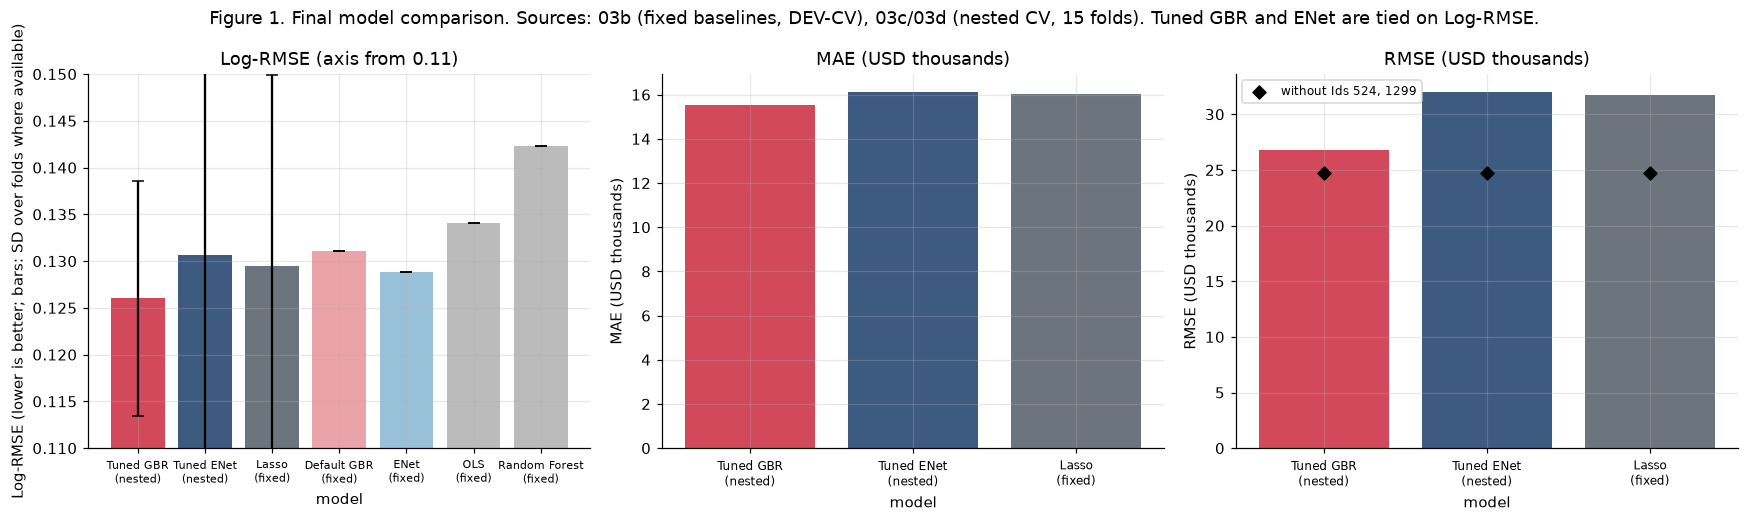

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
labels = ['Tuned GBR\n(nested)', 'Tuned ENet\n(nested)', 'Lasso\n(fixed)', 'Default GBR\n(fixed)', 'ENet\n(fixed)', 'OLS\n(fixed)', 'Random Forest\n(fixed)']
vals = [V('ACC-GBR-LOGRMSE'), V('ACC-ENET-LOGRMSE'), V('ACC-LASSO-LOGRMSE'), V('BASE-GBR-LOGRMSE'), V('BASE-ELASTICNET-LOGRMSE'), V('BASE-OLS-LOGRMSE'), V('BASE-RF-LOGRMSE')]
sds = [V('ACC-GBR-LOGRMSE-SD'), V('ACC-ENET-LOGRMSE-SD'), V('ACC-LASSO-LOGRMSE-SD'), 0, 0, 0, 0]
cols = ['#d1495b', '#3d5a80', '#6c757d', '#e9a3a9', '#98c1d9', '#bbbbbb', '#bbbbbb']
axes[0].bar(range(7), vals, yerr=sds, color=cols, capsize=4); axes[0].set_ylim(.11, .15); axes[0].set_xticks(range(7)); axes[0].set_xticklabels(labels, fontsize=7); axes[0].set_ylabel('Log-RMSE (lower is better; bars: SD over folds where available)'); axes[0].set_xlabel('model'); axes[0].set_title('Log-RMSE (axis from 0.11)')
for ax, key, ttl, sc_ in [(axes[1], 'MAE', 'MAE (USD thousands)', 1e3), (axes[2], 'RMSE', 'RMSE (USD thousands)', 1e3)]:
    ax.bar(range(3), [V(f'ACC-GBR-{key}') / sc_, V(f'ACC-ENET-{key}') / sc_, V(f'ACC-LASSO-{key}') / sc_], color=cols[:3]); ax.set_xticks(range(3)); ax.set_xticklabels(labels[:3], fontsize=8); ax.set_ylabel(ttl); ax.set_xlabel('model'); ax.set_title(ttl)
axes[2].scatter([0, 1, 2], [V('OUT-GBR-NOFLAG-RMSE') / 1e3, V('OUT-ENET-NOFLAG-RMSE') / 1e3, V('OUT-LASSO-NOFLAG-RMSE') / 1e3], color='k', marker='D', zorder=3, label='without Ids 524, 1299'); axes[2].legend(fontsize=8)
fig.suptitle('Figure 1. Final model comparison. Sources: 04 (fixed baselines, DEV-CV), 05/06 (nested CV, 15 folds). Tuned GBR and ENet are tied on Log-RMSE.'); plt.tight_layout(); plt.savefig(FIG / 'final_fig1_model_comparison.png'); plt.show()
spread = max(vals[:3]) - min(vals[:3])
MD(f'**Interpretation.** The three leading models are within {spread:.4f} Log-RMSE of each other, well inside the fold-to-fold SD ({max(sds[:3]):.4f}); GBR leads clearly only on USD RMSE and only when the two atypical houses are scored (black diamonds: without them the three RMSEs coincide). Random Forest ({V("BASE-RF-LOGRMSE"):.4f}) and OLS ({V("BASE-OLS-LOGRMSE"):.4f}) are behind the regularised and boosted models.')

## 6. Feature Interpretation without SHAP

In [8]:
groups = sorted({c.split('-')[1] for c in REG.claim_id if c.startswith('PI-') and c.endswith('-GBR')})
PIG = {g: (V(f'PI-{g}-GBR'), V(f'PI-{g}-GBR-SD'), V(f'PI-{g}-ENET'), V(f'PI-{g}-ENET-SD')) for g in groups}
pi_df = pd.DataFrame(PIG, index=['GBR mean', 'GBR SD', 'ENet mean', 'ENet SD']).T
pi_df['GBR rank'] = pi_df['GBR mean'].rank(ascending=False).astype(int); pi_df['ENet rank'] = pi_df['ENet mean'].rank(ascending=False).astype(int)
display(pi_df.sort_values('GBR mean', ascending=False).round(4))
NOTE = {'quality_and_condition': 'OverallQual/OverallCond and the exterior, kitchen and heating quality ratings', 'living_space': 'GrLivArea, floor areas, room and bedroom counts', 'location_and_lot': 'Neighborhood, zoning, lot size and shape', 'basement': 'basement area, finish, quality, exposure', 'property_age': 'YearBuilt and YearRemodAdd (as ages)',
        'garage': 'garage capacity, area, type, finish, quality', 'bathrooms': 'full and half baths above grade and in the basement', 'amenities_and_other': 'fireplaces, decks, porches, fence, central air and others', 'dwelling_type_and_exterior': 'dwelling type, style, roof, foundation, exterior materials'}
ABLN = {'living_space': ('ABL-LIVING-NONE-RIDGE', 'ABL-LIVING-NONE-GBR'), 'garage': ('ABL-GARAGE-NONE-RIDGE', 'ABL-GARAGE-NONE-GBR'), 'bathrooms': ('ABL-BATH-NONE-RIDGE', 'ABL-BATH-NONE-GBR')}
rows = []
for g, r in pi_df.sort_values('GBR mean', ascending=False).iterrows():
    abl = f"; ablation (all of the group's information removed, refit): Ridge {V(ABLN[g][0]):+.4f}, GBR {V(ABLN[g][1]):+.4f} Log-RMSE" if g in ABLN else ''
    rows.append({'Feature Group': g.replace('_', ' ').capitalize(), 'Evidence Method': 'Grouped permutation importance (held-out outer folds, 15 folds x 5 shuffles)' + (' + feature ablation' if abl else ''),
                 'Observed Importance': f"GBR +{r['GBR mean']:.4f} (SD {r['GBR SD']:.4f}), rank {int(r['GBR rank'])}; ElasticNet +{r['ENet mean']:.4f} (SD {r['ENet SD']:.4f}), rank {int(r['ENet rank'])}{abl}",
                 'Interpretation': f"Group = {NOTE[g]}. Predictive reliance of the fitted model; " + ('consistently important in both models' if max(r['GBR rank'], r['ENet rank']) <= 4 else 'moderate in both' if max(r['GBR rank'], r['ENet rank']) <= 7 else 'small in at least one model'),
                 'Limitation': 'Correlated with other groups (size, garage, basement, age); permutation can understate members of correlated sets; not causal'})
TB = pd.DataFrame(rows); print('Table B. Important predictive feature groups'); display(TB.set_index('Feature Group'))
TB.to_csv(TAB / 'final_table_B_feature_groups.csv', index=False)

,GBR mean,GBR SD,ENet mean,ENet SD,GBR rank,ENet rank
quality_and_condition,0.0981,0.0161,0.0723,0.0162,1,2
living_space,0.0661,0.0082,0.0977,0.0167,2,1
basement,0.0346,0.0050,0.0163,0.0041,3,4
location_and_lot,0.0240,0.0075,0.0309,0.0075,4,3
property_age,0.0145,0.0037,0.0154,0.0029,5,5
garage,0.0138,0.0036,0.0146,0.0044,6,6
bathrooms,0.0110,0.0025,0.0083,0.0031,7,9
amenities_and_other,0.0100,0.0040,0.0098,0.0040,8,7
dwelling_type_and_exterior,0.0010,0.0016,0.0090,0.0046,9,8


Table B. Important predictive feature groups


,Evidence Method,Observed Importance,Interpretation,Limitation
Feature Group,,,,
Quality and condition,"Grouped permutation importance (held-out outer folds, 15 folds x 5 shuffles)","GBR +0.0981 (SD 0.0161), rank 1; ElasticNet +0.0723 (SD 0.0162), rank 2","Group = OverallQual/OverallCond and the exterior, kitchen and heating quality ratings. Predictive reliance...","Correlated with other groups (size, garage, basement, age); permutation can understate members of correlat..."
Living space,"Grouped permutation importance (held-out outer folds, 15 folds x 5 shuffles) + feature ablation","GBR +0.0661 (SD 0.0082), rank 2; ElasticNet +0.0977 (SD 0.0167), rank 1; ablation (all of the group's info...","Group = GrLivArea, floor areas, room and bedroom counts. Predictive reliance of the fitted model; consiste...","Correlated with other groups (size, garage, basement, age); permutation can understate members of correlat..."
Basement,"Grouped permutation importance (held-out outer folds, 15 folds x 5 shuffles)","GBR +0.0346 (SD 0.0050), rank 3; ElasticNet +0.0163 (SD 0.0041), rank 4","Group = basement area, finish, quality, exposure. Predictive reliance of the fitted model; consistently im...","Correlated with other groups (size, garage, basement, age); permutation can understate members of correlat..."
Location and lot,"Grouped permutation importance (held-out outer folds, 15 folds x 5 shuffles)","GBR +0.0240 (SD 0.0075), rank 4; ElasticNet +0.0309 (SD 0.0075), rank 3","Group = Neighborhood, zoning, lot size and shape. Predictive reliance of the fitted model; consistently im...","Correlated with other groups (size, garage, basement, age); permutation can understate members of correlat..."
Property age,"Grouped permutation importance (held-out outer folds, 15 folds x 5 shuffles)","GBR +0.0145 (SD 0.0037), rank 5; ElasticNet +0.0154 (SD 0.0029), rank 5",Group = YearBuilt and YearRemodAdd (as ages). Predictive reliance of the fitted model; moderate in both,"Correlated with other groups (size, garage, basement, age); permutation can understate members of correlat..."
Garage,"Grouped permutation importance (held-out outer folds, 15 folds x 5 shuffles) + feature ablation","GBR +0.0138 (SD 0.0036), rank 6; ElasticNet +0.0146 (SD 0.0044), rank 6; ablation (all of the group's info...","Group = garage capacity, area, type, finish, quality. Predictive reliance of the fitted model; moderate in...","Correlated with other groups (size, garage, basement, age); permutation can understate members of correlat..."
Bathrooms,"Grouped permutation importance (held-out outer folds, 15 folds x 5 shuffles) + feature ablation","GBR +0.0110 (SD 0.0025), rank 7; ElasticNet +0.0083 (SD 0.0031), rank 9; ablation (all of the group's info...",Group = full and half baths above grade and in the basement. Predictive reliance of the fitted model; smal...,"Correlated with other groups (size, garage, basement, age); permutation can understate members of correlat..."
Amenities and other,"Grouped permutation importance (held-out outer folds, 15 folds x 5 shuffles)","GBR +0.0100 (SD 0.0040), rank 8; ElasticNet +0.0098 (SD 0.0040), rank 7","Group = fireplaces, decks, porches, fence, central air and others. Predictive reliance of the fitted model...","Correlated with other groups (size, garage, basement, age); permutation can understate members of correlat..."
Dwelling type and exterior,"Grouped permutation importance (held-out outer folds, 15 folds x 5 shuffles)","GBR +0.0010 (SD 0.0016), rank 9; ElasticNet +0.0090 (SD 0.0046), rank 8","Group = dwelling type, style, roof, foundation, exterior materials. Predictive reliance of the fitted mode...","Correlated with other groups (size, garage, basement, age); permutation can understate members of correlat..."


### 6.2 Chart: grouped permutation importance

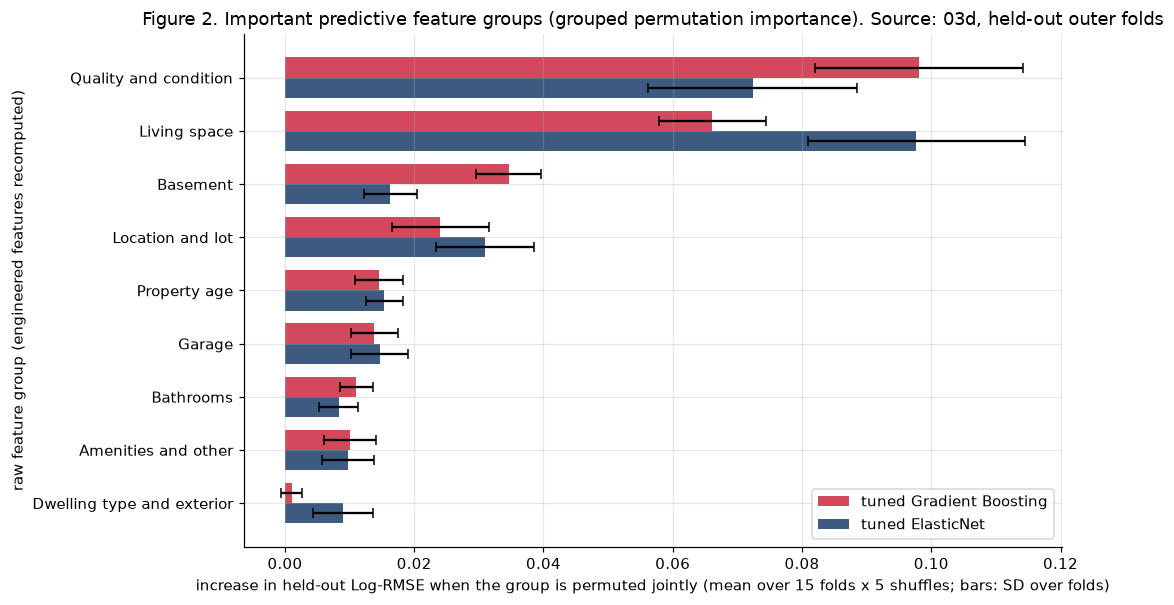

In [9]:
fig, ax = plt.subplots(figsize=(10, 5.6))
order = pi_df.sort_values('GBR mean').index
y_ = np.arange(len(order)); w = .38
ax.barh(y_ + w / 2, pi_df.loc[order, 'GBR mean'], w, xerr=pi_df.loc[order, 'GBR SD'], color='#d1495b', capsize=3, label='tuned Gradient Boosting')
ax.barh(y_ - w / 2, pi_df.loc[order, 'ENet mean'], w, xerr=pi_df.loc[order, 'ENet SD'], color='#3d5a80', capsize=3, label='tuned ElasticNet')
ax.set_yticks(y_); ax.set_yticklabels([o.replace('_', ' ').capitalize() for o in order]); ax.set_xlabel('increase in held-out Log-RMSE when the group is permuted jointly (mean over 15 folds x 5 shuffles; bars: SD over folds)'); ax.set_ylabel('raw feature group (engineered features recomputed)')
ax.set_title('Figure 2. Important predictive feature groups (grouped permutation importance). Source: 06, held-out outer folds'); ax.legend()
plt.tight_layout(); plt.savefig(FIG / 'final_fig2_feature_groups.png'); plt.show()

### 6.3 Regression coefficients of the final ElasticNet

In [10]:
import re
cf = pd.DataFrame([{'rank': i, 'feature (final ElasticNet, preprocessed)': re.search(r"of '(.*?)'", REG.loc[REG.claim_id == f'COEF-{i:02d}-PERSD', 'claim'].iloc[0]).group(1), 'standardised coefficient (per SD)': V(f'COEF-{i:02d}-PERSD'), 'approx. % change in price per original unit': V(f'COEF-{i:02d}-PCT'), 'elasticity if log1p input': V(f'COEF-{i:02d}-ELASTICITY')} for i in range(1, 11)]).set_index('rank')
print('C. Regression coefficients of the final ElasticNet (fit on all 1,460 houses; association only; NOT an explanation of the GBR):'); display(cf.round(4))
rc = V('PI-RANKCORR')
agree = [g for g in pi_df.index if max(pi_df.loc[g, 'GBR rank'], pi_df.loc[g, 'ENet rank']) <= 4]
conflict = [g for g in pi_df.index if abs(pi_df.loc[g, 'GBR rank'] - pi_df.loc[g, 'ENet rank']) >= 3]
MD(f'''
**A/B. Grouped permutation importance.** Ranked by the evidence (not assumed in advance): {', '.join(f"{g.replace('_', ' ')} (GBR rank {int(pi_df.loc[g, 'GBR rank'])}, ENet rank {int(pi_df.loc[g, 'ENet rank'])})" for g in pi_df.sort_values('GBR mean', ascending=False).index[:4])} lead; the evaluation metric is the rise in held-out Log-RMSE, the data are the 15 outer validation folds, each importance is a mean over 5 shuffles with fold SD shown; groups are listed in the table with their raw-column definitions (engineered ages and totals are recomputed from the shuffled raw columns).
**C. Coefficients (ElasticNet only).** The largest standardised coefficients belong to {', '.join(cf['feature (final ElasticNet, preprocessed)'].head(5))}. Because the target is log1p(price), `OverallQual` is associated with about {V('COEF-02-PCT'):.1f}% higher price per quality point (an approximate multiplicative association, not a dollar effect) and living area enters through log1p, so its coefficient ({V('COEF-01-ELASTICITY'):.2f}) is an elasticity. {int(V('CX-ENET-NONZERO'))} of {int(V('CX-ENET-COLUMNS'))} coefficients are non-zero; correlated predictors share coefficient mass, so individual values are unstable.
**D. Feature ablation (notebook 03).** Removing *all* living-space information raises Log-RMSE by {V('ABL-LIVING-NONE-RIDGE'):.4f} (Ridge) and {V('ABL-LIVING-NONE-GBR'):.4f} (GBR); removing both garage columns {V('ABL-GARAGE-NONE-RIDGE'):.4f} and {V('ABL-GARAGE-NONE-GBR'):.4f}; removing all bathroom information {V('ABL-BATH-NONE-RIDGE'):.4f} and {V('ABL-BATH-NONE-GBR'):.4f}; keeping *both* garage columns changes nothing measurable ({V('ABL-GARAGE-BOTH-RIDGE'):+.4f}, {V('ABL-GARAGE-BOTH-GBR'):+.4f}). Ablation measures what is lost when information is removed and the model refit, so correlated substitutes compensate: ablation costs are smaller than permutation importances.
**E. Agreement.** The group importances of the two models are correlated (Spearman {rc:.2f} over nine groups); groups important in both (rank <= 4 in each): {', '.join(g.replace('_', ' ') for g in agree) or 'none'}; groups whose rank differs by three or more places: {', '.join(g.replace('_', ' ') for g in conflict) or 'none'}. Size-related groups (living space, basement, garage) are correlated with each other, so their individual importances are not additive. All four methods measure *predictive association or model behaviour*, not causal effects on price: they cannot say that renovating, adding a garage or moving would change a price.
''')

C. Regression coefficients of the final ElasticNet (fit on all 1,460 houses; association only; NOT an explanation of the GBR):


,"feature (final ElasticNet, preprocessed)",standardised coefficient (per SD),approx. % change in price per original unit,elasticity if log1p input
rank,,,,
1,GrLivArea,0.1407,NaN,0.4222
2,OverallQual,0.0748,5.5600,NaN
3,OverallCond,0.0449,4.1184,NaN
4,HouseAge,-0.0426,-0.1409,NaN
5,LotArea,0.0404,NaN,0.0780
6,GarageCars,0.0383,5.2579,NaN
7,TotalBathrooms,0.0312,4.0474,NaN
8,Neighborhood_NridgHt,0.0215,10.0828,NaN
9,MSZoning_C (all),-0.0214,-22.8284,NaN


## 7. Prediction Uncertainty

In [11]:
MD(f'''
**Method.** Split conformalized quantile regression (CQR): two quantile gradient-boosting models (alpha 0.10 and 0.90, a fixed configuration not tuned for quantile loss) fitted on a proper-training part, a correction q_hat computed from conformity scores on a disjoint calibration part (k = ceil((n_cal + 1)(1 - alpha))), applied on the log1p scale and then converted to dollars. Everything was recreated inside each outer fold (proper-training 75% / calibration 25% / evaluation fold).

**Meaning of an 80% interval.** If calibration and evaluation houses are exchangeable, about 80% of houses on average have a sale price inside their interval. It is a statement about the *average over houses*, not about one property, and not about a given neighbourhood or price band.

| | Nominal | Empirical coverage | Gap (pp) | Mean width | Median relative width |
|---|---|---|---|---|---|
| Raw quantile GB | 80% | {sh(V('INT-RAW-COVERAGE'))} | {V('INT-RAW-GAP'):+.1f} | {usd(V('INT-RAW-MEANWIDTH'))} | {p1(V('INT-RAW-MEDRELWIDTH'))} |
| CQR (used) | 80% | {sh(V('INT-CQR-COVERAGE'))} | {V('INT-CQR-GAP'):+.1f} | {usd(V('INT-CQR-MEANWIDTH'))} | {p1(V('INT-CQR-MEDRELWIDTH'))} |

*Source: 07 (NESTED-style out-of-fold; 1,460 houses per repeat).* Calibration widened the intervals by {100 * (V('INT-CQR-MEANWIDTH') / V('INT-RAW-MEANWIDTH') - 1):.0f}% to reach the target. The point prediction lies outside the CQR interval for {sh(V('INT-CQR-POINT-OUTSIDE'))} of houses (and outside the raw interval for {sh(V('INT-RAW-POINT-OUTSIDE'))}); it is not forced inside. **Assumptions and limits:** exchangeability of calibration and evaluation houses; marginal coverage only (no guarantee for any neighbourhood, price band, routing group or single property); not valid under distribution shift without further assumptions: under the chronological split CQR covered {sh(V('INT-TEMP-CQR-COVERAGE'))} on average (range {sh(V('INT-TEMP-CQR-COVERAGE-MIN'))} to {sh(V('INT-TEMP-CQR-COVERAGE-MAX'))} across 20 calibration splits).
''')

### 7.2 Interval coverage and width by segment (table)

In [12]:
seg_specs = [('Price (predicted, deployable)', 'price (predicted)', ['low', 'mid', 'luxury']), ('Quality (OverallQual)', 'quality tier', ['low (1-4)', 'medium (5-8)', 'high (9-10)']), ('Property age', 'age group', ['<=10 yr', '11-30 yr', '31-60 yr', '>60 yr']),
             ('Living area', 'living area', ['<=1,200 sq ft', '1,201-1,800', '>1,800 sq ft']), ('Sale year (metadata)', 'sale year', ['2006', '2007', '2008', '2009', '2010'])]
sc_tab = pd.read_csv(TAB / 'segments_consolidated.csv'); nb_groups = sc_tab[sc_tab['Segment Type'] == 'Neighbourhood (n >= 30)'].Group.tolist()
seg_specs.append(('Neighbourhood (n >= 30)', 'neighbourhood', nb_groups))
rows = []
for typ, pref, grs in seg_specs:
    for gname in grs:
        s_ = lambda m: V(f'SEG-{slug(typ)}-{slug(gname)}-{m}'); i_ = lambda m: V(f'INTSEG-{slug(pref + ": " + gname)}-{m}')
        rows.append({'type': typ, 'Property Segment': f'{typ.split(" (")[0]}: {gname}', 'n': s_('N'), 'MAE': s_('MAE'), 'MAPE': s_('MAPE'), 'Log-RMSE': s_('LOGRMSE'), 'signed': s_('SIGNED'), 'coverage': i_('COVERAGE'), 'width_pct': i_('MEDRELWIDTH')})
SG = pd.DataFrame(rows)
OVR_MAPE, OVR_MAE = V('RT-P-OVERALLMAPE'), V('RT-P-OVERALLMAE')
def label(r):
    if r.type.startswith('Sale year'): return 'Monitoring only (not a deployable grouping)'
    if r.MAPE >= 1.25 * OVR_MAPE or r.coverage < 0.75 or r.MAE >= 2 * OVR_MAE: return 'REVIEW PRIORITY: higher error or weak coverage'
    if r.n < 100: return 'Insufficient sample for a firm recommendation'
    if r.MAPE <= OVR_MAPE and r.coverage >= 0.78: return 'Reliable relative to the portfolio'
    return 'Standard use with the interval shown'
SG['Recommendation'] = SG.apply(label, axis=1)
TC = SG.assign(**{'Sample Size': SG.n.round(0).astype(int), 'Error Metric': SG.apply(lambda r: f'MAE {usd(r.MAE)}; MAPE {r.MAPE:.1f}%; Log-RMSE {r["Log-RMSE"]:.3f}; signed {usd(r.signed)}', axis=1), 'Interval Coverage': SG.coverage.map(sh) + SG.width_pct.map(lambda w: f' (median width {w:.0f}%)')})[['Property Segment', 'Sample Size', 'Error Metric', 'Interval Coverage', 'Recommendation']]
print(f'Table C. Segment reliability (tuned GBR, NESTED-CV out-of-fold; labels follow a rule fixed in advance: REVIEW PRIORITY if MAPE >= 1.25 x portfolio MAPE ({p2(OVR_MAPE)}), or coverage < 75%, or MAE >= 2 x portfolio MAE ({usd(OVR_MAE)}); Reliable if n >= 100, MAPE <= portfolio MAPE and coverage >= 78%)')
display(TC.set_index('Property Segment')); TC.to_csv(TAB / 'final_table_C_segment_reliability.csv', index=False)

Table C. Segment reliability (tuned GBR, NESTED-CV out-of-fold; labels follow a rule fixed in advance: REVIEW PRIORITY if MAPE >= 1.25 x portfolio MAPE (8.76%), or coverage < 75%, or MAE >= 2 x portfolio MAE ($15,535); Reliable if n >= 100, MAPE <= portfolio MAPE and coverage >= 78%)


,Sample Size,Error Metric,Interval Coverage,Recommendation
Property Segment,,,,
Price: low,371,"MAE $10,280; MAPE 10.6%; Log-RMSE 0.150; signed $972",80.9% (median width 36%),Standard use with the interval shown
Price: mid,947,"MAE $13,563; MAPE 7.4%; Log-RMSE 0.103; signed $1,289",81.0% (median width 23%),Reliable relative to the portfolio
Price: luxury,142,"MAE $42,402; MAPE 13.1%; Log-RMSE 0.189; signed $5,045",78.4% (median width 43%),REVIEW PRIORITY: higher error or weak coverage
Quality: low (1-4),141,"MAE $12,275; MAPE 13.8%; Log-RMSE 0.184; signed $1,533",79.4% (median width 48%),REVIEW PRIORITY: higher error or weak coverage
Quality: medium (5-8),1258,"MAE $14,165; MAPE 7.9%; Log-RMSE 0.110; signed $1,055",80.9% (median width 25%),Reliable relative to the portfolio
Quality: high (9-10),61,"MAE $51,321; MAPE 14.7%; Log-RMSE 0.229; signed $12,493",79.2% (median width 50%),REVIEW PRIORITY: higher error or weak coverage
Property age: <=10 yr,388,"MAE $20,353; MAPE 8.2%; Log-RMSE 0.127; signed $1,755",81.7% (median width 25%),Reliable relative to the portfolio
Property age: 11-30 yr,224,"MAE $17,976; MAPE 7.1%; Log-RMSE 0.101; signed $3,680",83.3% (median width 23%),Reliable relative to the portfolio
Property age: 31-60 yr,530,"MAE $11,561; MAPE 7.9%; Log-RMSE 0.114; signed $827",81.1% (median width 25%),Reliable relative to the portfolio


### 7.3 Chart: coverage by segment with recommendation class

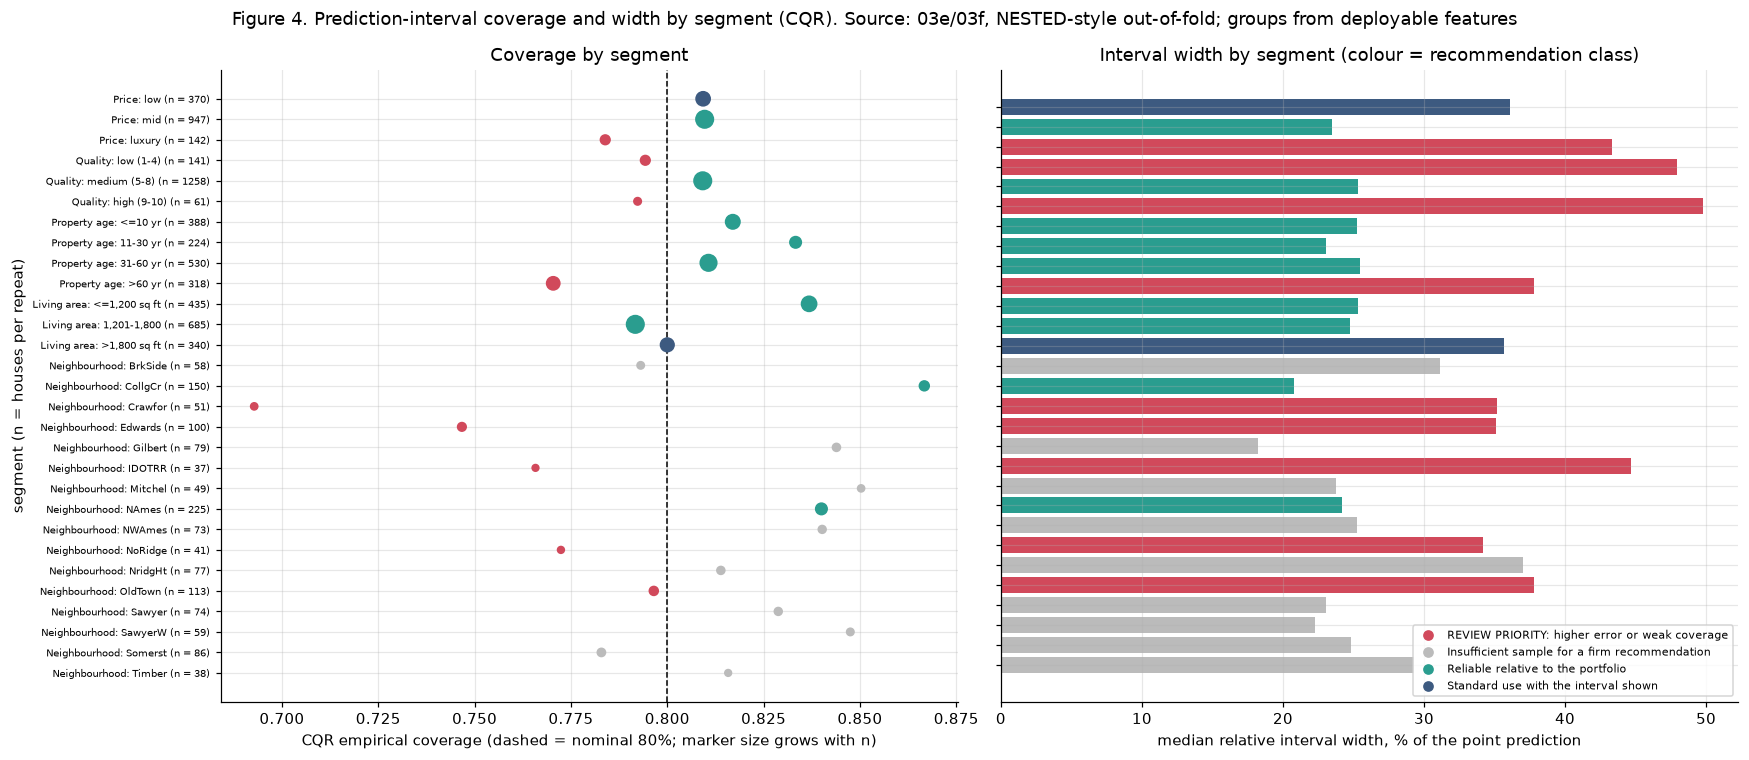

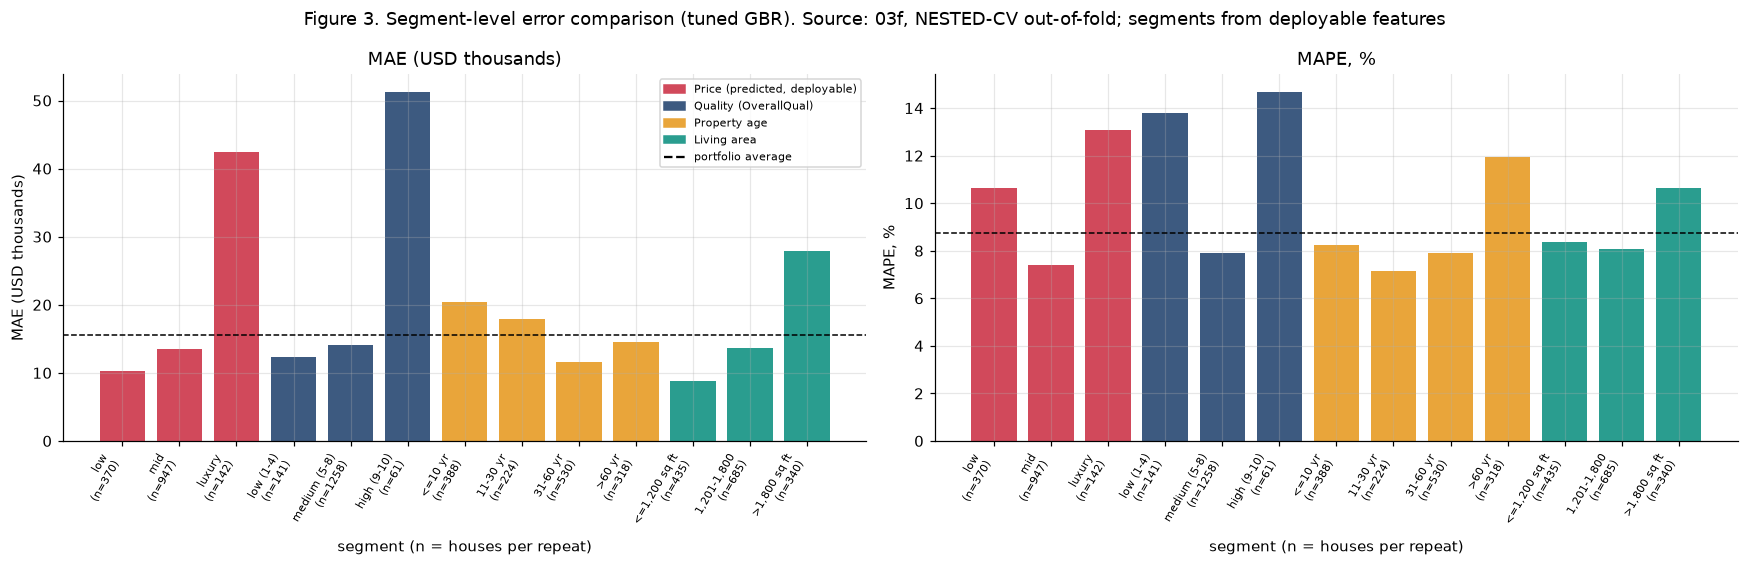

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7), gridspec_kw={'width_ratios': [1, 1]})
sg = SG[~SG.type.str.startswith('Sale year')].iloc[::-1]
cmap = {'REVIEW PRIORITY: higher error or weak coverage': '#d1495b', 'Insufficient sample for a firm recommendation': '#bbbbbb', 'Reliable relative to the portfolio': '#2a9d8f', 'Standard use with the interval shown': '#3d5a80'}
axes[0].scatter(sg.coverage, range(len(sg)), c=[cmap[l] for l in sg.Recommendation], s=np.clip(sg.n, 20, 600) / 5 + 12, zorder=3)
axes[0].axvline(.8, color='k', ls='--', lw=1); axes[0].set_yticks(range(len(sg))); axes[0].set_yticklabels([f'{a} (n = {int(n)})' for a, n in zip(sg['Property Segment'], sg.n)], fontsize=6.5)
axes[0].set_xlabel('CQR empirical coverage (dashed = nominal 80%; marker size grows with n)'); axes[0].set_ylabel('segment (n = houses per repeat)'); axes[0].set_title('Coverage by segment')
axes[1].barh(range(len(sg)), sg.width_pct, color=[cmap[l] for l in sg.Recommendation]); axes[1].set_yticks(range(len(sg))); axes[1].set_yticklabels([]); axes[1].set_xlabel('median relative interval width, % of the point prediction'); axes[1].set_title('Interval width by segment (colour = recommendation class)')
handles = [plt.Line2D([0], [0], marker='o', ls='', color=c, label=l) for l, c in cmap.items()]; axes[1].legend(handles=handles, fontsize=7, loc='lower right')
fig.suptitle('Figure 4. Prediction-interval coverage and width by segment (CQR). Source: 07/08, NESTED-style out-of-fold; groups from deployable features'); plt.tight_layout(); plt.savefig(FIG / 'final_fig4_interval_coverage_width.png'); plt.show()
fig, axes = plt.subplots(1, 2, figsize=(16, 5.2))
sg2 = SG[SG.type.isin(['Price (predicted, deployable)', 'Quality (OverallQual)', 'Property age', 'Living area'])]
cl = {'Price (predicted, deployable)': '#d1495b', 'Quality (OverallQual)': '#3d5a80', 'Property age': '#e9a53a', 'Living area': '#2a9d8f'}
for ax, key, ttl, sc_ in [(axes[0], 'MAE', 'MAE (USD thousands)', 1e3), (axes[1], 'MAPE', 'MAPE, %', 1)]:
    ax.bar(range(len(sg2)), sg2[key] / sc_, color=[cl[t] for t in sg2.type]); ax.set_xticks(range(len(sg2))); ax.set_xticklabels([f"{p.split(': ')[1]}\n(n={int(n)})" for p, n in zip(sg2['Property Segment'], sg2.n)], rotation=60, ha='right', fontsize=7)
    ax.axhline((OVR_MAE if key == 'MAE' else OVR_MAPE) / sc_, color='k', ls='--', lw=1, label='portfolio average'); ax.set_ylabel(ttl); ax.set_xlabel('segment (n = houses per repeat)'); ax.set_title(ttl)
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in cl.values()]; axes[0].legend(handles + [plt.Line2D([0], [0], color='k', ls='--')], list(cl) + ['portfolio average'], fontsize=7)
fig.suptitle('Figure 3. Segment-level error comparison (tuned GBR). Source: 08, NESTED-CV out-of-fold; segments from deployable features'); plt.tight_layout(); plt.savefig(FIG / 'final_fig3_segment_errors.png'); plt.show()

## 8. Property Segment Findings

In [14]:
S = lambda typ, g, m: V(f'SEG-{slug(typ)}-{slug(g)}-{m}'); I = lambda pref, g, m: V(f'INTSEG-{slug(pref + ": " + g)}-{m}')
nb = SG[SG.type == 'Neighbourhood (n >= 30)'].set_index('Property Segment')
best_nb = nb.sort_values('MAPE').head(3); worst_nb = nb.sort_values('MAPE', ascending=False).head(3)
MD(f'''
*All figures: tuned GBR, NESTED-CV out-of-fold, groups from deployable features unless stated; sample sizes are houses per repeat; observed differences are descriptive unless stated, and none is causal.*
* **Price (predicted).** MAE {kd(S('Price (predicted, deployable)', 'low', 'MAE'))} / {kd(S('Price (predicted, deployable)', 'mid', 'MAE'))} / {kd(S('Price (predicted, deployable)', 'luxury', 'MAE'))} for low / mid / luxury (n = {S('Price (predicted, deployable)', 'low', 'N'):.0f} / {S('Price (predicted, deployable)', 'mid', 'N'):.0f} / {S('Price (predicted, deployable)', 'luxury', 'N'):.0f}); MAPE {p1(S('Price (predicted, deployable)', 'low', 'MAPE'))} / {p1(S('Price (predicted, deployable)', 'mid', 'MAPE'))} / {p1(S('Price (predicted, deployable)', 'luxury', 'MAPE'))}. Dollar errors grow with price (errors are roughly proportional), percentage errors are highest at both ends; luxury coverage {sh(I('price (predicted)', 'luxury', 'COVERAGE'))} on {S('Price (predicted, deployable)', 'luxury', 'N'):.0f} houses (not distinguishable from 80%). Segments by *realised* price are retrospective diagnostics and affected by regression to the mean.
* **Quality.** MAPE {p1(S('Quality (OverallQual)', 'low (1-4)', 'MAPE'))} (quality 1-4, n = {S('Quality (OverallQual)', 'low (1-4)', 'N'):.0f}), {p1(S('Quality (OverallQual)', 'medium (5-8)', 'MAPE'))} (5-8, n = {S('Quality (OverallQual)', 'medium (5-8)', 'N'):.0f}), {p1(S('Quality (OverallQual)', 'high (9-10)', 'MAPE'))} (9-10, n = {S('Quality (OverallQual)', 'high (9-10)', 'N'):.0f}); the high-quality group is small and contains both atypical houses.
* **Neighbourhood (n >= 30).** Lowest MAPE: {', '.join(f"{i.split(': ')[1]} ({r.MAPE:.1f}%, n={int(r.n)})" for i, r in best_nb.iterrows())}; highest: {', '.join(f"{i.split(': ')[1]} ({r.MAPE:.1f}%, n={int(r.n)})" for i, r in worst_nb.iterrows())}; many intervals overlap (08: only the better-than-average results of CollgCr, Gilbert and SawyerW are statistically supported). Edwards contains both atypical houses. Neighbourhood size shows no relation to error in 08.
* **Property age.** Houses older than 60 years have MAPE {p1(S('Property age', '>60 yr', 'MAPE'))} against {p1(S('Property age', '11-30 yr', 'MAPE'))}-{p1(S('Property age', '31-60 yr', 'MAPE'))} for younger groups, and CQR coverage {sh(I('age group', '>60 yr', 'COVERAGE'))}; the newest houses have the largest dollar error ({kd(S('Property age', '<=10 yr', 'MAE'))}) because they are expensive.
* **Living area.** MAE {kd(S('Living area', '<=1,200 sq ft', 'MAE'))} -> {kd(S('Living area', '1,201-1,800', 'MAE'))} -> {kd(S('Living area', '>1,800 sq ft', 'MAE'))} by size group; no clear large-house underprediction (signed error {usd(S('Living area', '>1,800 sq ft', 'SIGNED'))}).
* **Sale year (metadata, random-CV model; not temporal validation).** MAPE {p1(S('Sale year (metadata)', '2006', 'MAPE'))} (2006) to {p1(S('Sale year (metadata)', '2009', 'MAPE'))} (2009); no year is distinguishable. The mean signed error moves from {usd(S('Sale year (metadata)', '2006', 'SIGNED'))} (2006) to {usd(S('Sale year (metadata)', '2009', 'SIGNED'))} (2009): later sales are slightly overpredicted.
* **Limitations.** Small groups ({S('Quality (OverallQual)', 'high (9-10)', 'N'):.0f} houses with quality 9-10; {int(min(SG[SG.type == 'Neighbourhood (n >= 30)'].n))}-{int(max(SG[SG.type == 'Neighbourhood (n >= 30)'].n))} houses in the neighbourhoods shown); many overlapping comparisons; two atypical sales distort luxury, high-quality, newest-house and Edwards dollar figures.
''')

## 9. Temporal Generalisation

In [15]:
MD(f'''
**Design.** Train on houses sold 2006-2008 ({int(V('TEMP-NTRAIN'))} houses), test on 2009-2010 ({int(V('TEMP-NTEST'))} houses): the split of notebook 03, reused unchanged. Preprocessing, hyperparameters (re-tuned by Optuna inside the training years) and calibration use training years only; sale year is never a predictor. **Why it matters:** valuation is applied to future sales in a market that moves; a random split lets the model see neighbours sold at the same time.

| | Log-RMSE | MAE | MAPE | USD R2 |
|---|---|---|---|---|
| Random 5-fold, nested-tuned (NESTED-CV; trains on ~1,168) | {lr(V('ACC-GBR-LOGRMSE'))} | {usd(V('ACC-GBR-MAE'))} | {p2(V('ACC-GBR-MAPE'))} | {V('ACC-GBR-R2'):.3f} |
| 30 random splits, same sizes (947 / 513), fixed config, mean (DEV-CV) | {lr(V('RAND947-GBR-LOGRMSE-MEAN'))} | n/a | n/a | n/a |
| **Chronological holdout (TEMPORAL), historical-only tuned GBR** | **{lr(V('TEMP-GBR-LOGRMSE'))}** | {usd(V('TEMP-GBR-MAE'))} | {p2(V('TEMP-GBR-MAPE'))} | {V('TEMP-GBR-R2'):.3f} |
| Chronological holdout, historical-only tuned ElasticNet | {lr(V('TEMP-ENET-LOGRMSE'))} | {usd(V('TEMP-ENET-MAE'))} | {p2(V('TEMP-ENET-MAPE'))} | {V('TEMP-ENET-R2'):.3f} |

**Reading.** The chronological result is modestly worse than random CV, but the designs differ in training size, test composition (the temporal test set contains neither atypical house, which also lifts its R2) and evaluation distribution; with the same fixed configuration the temporal Log-RMSE ({lr(V('TEMP-GBR-FIXED-LOGRMSE'))}) lies above the random-split mean ({lr(V('RAND947-GBR-LOGRMSE-MEAN'))} +/- {lr(V('RAND947-GBR-LOGRMSE-SD'))}; {lr(V('RAND947-GBR-LOGRMSE-NOFLAG-MEAN'))} when the atypical houses are matched). That is suggestive of a modest temporal effect, not proof. **Distribution shift** in the predictors is negligible (largest |standardised mean difference| {V('SHIFT-MAXABS-SMD'):.2f}, largest KS statistic {V('SHIFT-MAXKS'):.2f}); the temporal signed error is {usd(V('TEMP-GBR-SIGNED'))} (later sales slightly overpredicted), consistent with a small price-level drift that a model without a time input cannot see. Historical validation does not guarantee performance in a future market; it was one split of {int(V('TEMP-NTEST'))} houses in one city.
''')

### 9.2 Chart: random versus chronological Log-RMSE (registry values)

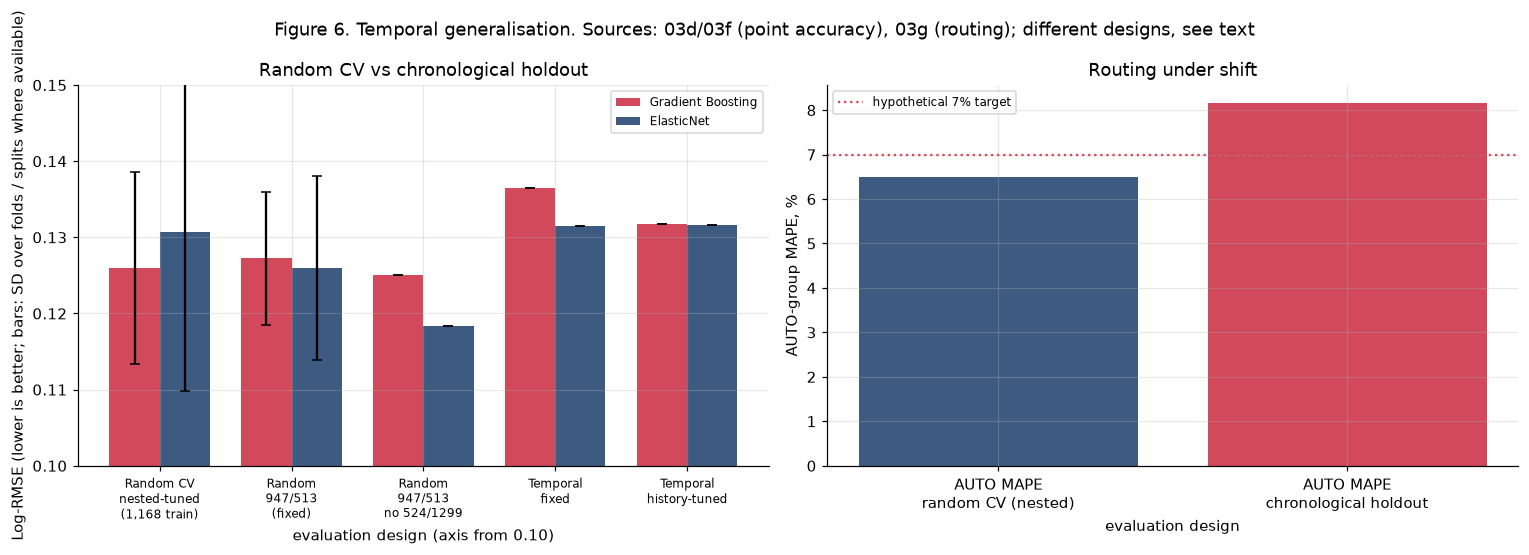

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
labs = ['Random CV\nnested-tuned\n(1,168 train)', 'Random\n947/513\n(fixed)', 'Random\n947/513\nno 524/1299', 'Temporal\nfixed', 'Temporal\nhistory-tuned']
w = .38; x = np.arange(5)
gv = [V('ACC-GBR-LOGRMSE'), V('RAND947-GBR-LOGRMSE-MEAN'), V('RAND947-GBR-LOGRMSE-NOFLAG-MEAN'), V('TEMP-GBR-FIXED-LOGRMSE'), V('TEMP-GBR-LOGRMSE')]
ev = [V('ACC-ENET-LOGRMSE'), V('RAND947-ENET-LOGRMSE-MEAN'), V('RAND947-ENET-LOGRMSE-NOFLAG-MEAN'), V('TEMP-ENET-FIXED-LOGRMSE'), V('TEMP-ENET-LOGRMSE')]
gs = [V('ACC-GBR-LOGRMSE-SD'), V('RAND947-GBR-LOGRMSE-SD'), 0, 0, 0]; es = [V('ACC-ENET-LOGRMSE-SD'), V('RAND947-ENET-LOGRMSE-SD'), 0, 0, 0]
axes[0].bar(x - w / 2, gv, w, yerr=gs, color='#d1495b', capsize=3, label='Gradient Boosting'); axes[0].bar(x + w / 2, ev, w, yerr=es, color='#3d5a80', capsize=3, label='ElasticNet')
axes[0].set_ylim(.10, .15); axes[0].set_xticks(x); axes[0].set_xticklabels(labs, fontsize=8); axes[0].set_ylabel('Log-RMSE (lower is better; bars: SD over folds / splits where available)'); axes[0].set_xlabel('evaluation design (axis from 0.10)'); axes[0].set_title('Random CV vs chronological holdout'); axes[0].legend(fontsize=8)
axes[1].bar([0, 1], [V('RT-P-AUTOMAPE'), V('RT-TEMP-P-AUTOMAPE')], color=['#3d5a80', '#d1495b']); axes[1].axhline(7, color='#d1495b', ls=':', label='hypothetical 7% target'); axes[1].set_xticks([0, 1]); axes[1].set_xticklabels(['AUTO MAPE\nrandom CV (nested)', 'AUTO MAPE\nchronological holdout']); axes[1].set_ylabel('AUTO-group MAPE, %'); axes[1].set_xlabel('evaluation design'); axes[1].set_title('Routing under shift'); axes[1].legend(fontsize=8)
fig.suptitle('Figure 6. Temporal generalisation. Sources: 06/08 (point accuracy), 09 (routing); different designs, see text'); plt.tight_layout(); plt.savefig(FIG / 'final_fig6_temporal.png'); plt.show()
MD('**Interpretation.** Point accuracy degrades modestly under the chronological split and the AUTO error rises past the hypothetical 7% target; both signs point the same way, and neither can be separated from the smaller training set and the composition of the 513 test houses with the evidence available.')

## 10. AUTO / ESCALATE Decision Support

In [17]:
D = pd.DataFrame([
    ('Routing signal and rule', 'relative interval width w = (U - L) / point prediction (USD); AUTO if w <= tau', 'Uses only prediction-time information; actual prices, errors and coverage never enter a live decision'),
    ('Threshold selection protocol', 'nested: tau chosen on inner out-of-fold development predictions of the outer-training houses, applied to the held-out fold; hypothetical target AUTO MAPE <= 7% (conservative 90% bound), AUTO N >= 100', 'The proposal gives no numeric target; the target is a labelled assumption'),
    ('Deployable threshold by the rule', f"tau = {V('RT-FINAL-TAUFINAL'):.2f} (fold-wise thresholds {V('RT-P-TAUK-MIN'):.2f}-{V('RT-P-TAUK-MAX'):.2f}, median {V('RT-P-TAUK-MEDIAN'):.2f}; bootstrap 10th-90th percentile {V('RT-FINAL-BOOTP10'):.2f}-{V('RT-FINAL-BOOTP90'):.2f})", 'Neighbouring thresholds are not distinguishable; the exact value has no independent evaluation'),
    ('AUTO share (held-out)', f"{p1(V('RT-P-AUTOSHARE'))} (CV repeats {sh(V('RT-P-AUTOSHARE-MIN-REPEAT'))}-{sh(V('RT-P-AUTOSHARE-MAX-REPEAT'))}); ESCALATE {p1(V('RT-P-ESCSHARE'))}", 'Automation volume is much less certain than automation accuracy'),
    ('AUTO error (held-out)', f"MAE {usd(V('RT-P-AUTOMAE'))}, RMSE {usd(V('RT-P-AUTORMSE'))}, MAPE {p2(V('RT-P-AUTOMAPE'))}", f"Average error of automated valuations; {sh(V('RT-P-AUTO-APE15'))} of them still exceed 15% error (95th percentile {p1(V('RT-P-AUTO-P95APE'))})"),
    ('AUTO interval coverage', f"{sh(V('RT-P-AUTOCOV'))} against nominal 80% (ESCALATE {sh(V('RT-P-ESCCOV'))})", 'Narrow-interval houses are less well covered: the marginal 80% does not carry to the AUTO subgroup'),
    ('ESCALATE error (automated prediction, before human review)', f"MAE {usd(V('RT-P-ESCMAE'))}, MAPE {p2(V('RT-P-ESCMAPE'))}", 'ESCALATE means higher expected error and uncertainty: a recommendation for review, not proof the prediction is wrong'),
    ('Overall (everything automated)', f"MAE {usd(V('RT-P-OVERALLMAE'))}, MAPE {p2(V('RT-P-OVERALLMAPE'))}, coverage {sh(V('RT-P-OVERALLCOV'))}", 'Reference point for the routing gain'),
    ('Temporal routing (threshold from 2006-2008)', f"tau {V('RT-TEMP-P-TAU'):.2f}: AUTO {p1(V('RT-TEMP-P-AUTOSHARE'))}, AUTO MAPE {p2(V('RT-TEMP-P-AUTOMAPE'))}, AUTO MAE {usd(V('RT-TEMP-P-AUTOMAE'))}, AUTO coverage {sh(V('RT-TEMP-P-AUTOCOV'))}, ESCALATE {p1(V('RT-TEMP-P-ESCSHARE'))} (MAPE {p2(V('RT-TEMP-P-ESCMAPE'))})", 'Random-CV routing performance does not carry over unchanged: the 7% target is not met on later years'),
    ('Other hypothetical scenarios (held-out)', f"6% target: AUTO {p1(V('RT-S6-AUTOSHARE'))} (MAPE {p2(V('RT-S6-AUTOMAPE'))}); 8% target: AUTO {p1(V('RT-S8-AUTOSHARE'))} (MAPE {p2(V('RT-S8-AUTOMAPE'))}); coverage >= 80% constraint: AUTO {p1(V('RT-S7COV-AUTOSHARE'))} (coverage {sh(V('RT-S7COV-AUTOCOV'))})", 'The threshold is a business decision; AUTO coverage cannot be bought with the threshold alone'),
], columns=['Routing Metric', 'Validated Result', 'Business Interpretation'])
print('Table D. Routing evidence (tuned GBR + CQR; ROUTING-NESTED unless stated; hypothetical target)'); display(D.set_index('Routing Metric')); D.to_csv(TAB / 'final_table_D_routing.csv', index=False)

Table D. Routing evidence (tuned GBR + CQR; ROUTING-NESTED unless stated; hypothetical target)


,Validated Result,Business Interpretation
Routing Metric,,
Routing signal and rule,relative interval width w = (U - L) / point prediction (USD); AUTO if w <= tau,"Uses only prediction-time information; actual prices, errors and coverage never enter a live decision"
Threshold selection protocol,"nested: tau chosen on inner out-of-fold development predictions of the outer-training houses, applied to t...",The proposal gives no numeric target; the target is a labelled assumption
Deployable threshold by the rule,"tau = 0.22 (fold-wise thresholds 0.18-0.34, median 0.26; bootstrap 10th-90th percentile 0.22-0.34)",Neighbouring thresholds are not distinguishable; the exact value has no independent evaluation
AUTO share (held-out),45.0% (CV repeats 37.9%-52.7%); ESCALATE 55.0%,Automation volume is much less certain than automation accuracy
AUTO error (held-out),"MAE $10,821, RMSE $16,468, MAPE 6.49%",Average error of automated valuations; 7.0% of them still exceed 15% error (95th percentile 17.0%)
AUTO interval coverage,78.5% against nominal 80% (ESCALATE 82.5%),Narrow-interval houses are less well covered: the marginal 80% does not carry to the AUTO subgroup
"ESCALATE error (automated prediction, before human review)","MAE $19,433, MAPE 10.66%","ESCALATE means higher expected error and uncertainty: a recommendation for review, not proof the predictio..."
Overall (everything automated),"MAE $15,535, MAPE 8.76%, coverage 80.7%",Reference point for the routing gain
Temporal routing (threshold from 2006-2008),"tau 0.32: AUTO 64.5%, AUTO MAPE 8.16%, AUTO MAE $12,618, AUTO coverage 75.5%, ESCALATE 35.5% (MAPE 12.44%)",Random-CV routing performance does not carry over unchanged: the 7% target is not met on later years


### 10.2 Chart and table: routing trade-off, nested policy against fixed thresholds

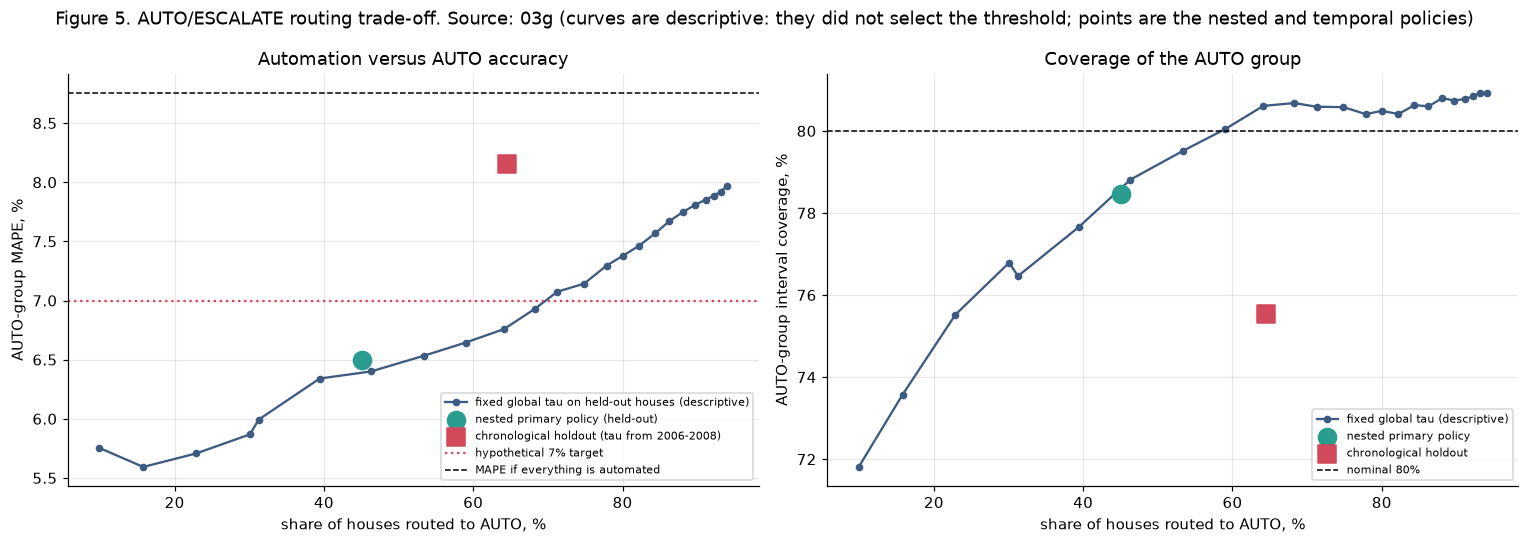

In [18]:
ev = pd.read_csv(TAB / 'routing_threshold_comparison_evaluation_descriptive.csv')
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(ev.auto_share, ev.auto_mape, 'o-', color='#3d5a80', ms=4, label='fixed global tau on held-out houses (descriptive)')
axes[0].scatter([V('RT-P-AUTOSHARE')], [V('RT-P-AUTOMAPE')], s=140, color='#2a9d8f', zorder=4, label='nested primary policy (held-out)'); axes[0].scatter([V('RT-TEMP-P-AUTOSHARE')], [V('RT-TEMP-P-AUTOMAPE')], s=140, color='#d1495b', marker='s', zorder=4, label='chronological holdout (tau from 2006-2008)')
axes[0].axhline(7, color='#d1495b', ls=':', lw=1.5, label='hypothetical 7% target'); axes[0].axhline(V('RT-P-OVERALLMAPE'), color='k', ls='--', lw=1, label='MAPE if everything is automated')
axes[0].set_xlabel('share of houses routed to AUTO, %'); axes[0].set_ylabel('AUTO-group MAPE, %'); axes[0].set_title('Automation versus AUTO accuracy'); axes[0].legend(fontsize=7)
axes[1].plot(ev.auto_share, 100 * ev.auto_coverage, 'o-', color='#3d5a80', ms=4, label='fixed global tau (descriptive)'); axes[1].scatter([V('RT-P-AUTOSHARE')], [100 * V('RT-P-AUTOCOV')], s=140, color='#2a9d8f', zorder=4, label='nested primary policy'); axes[1].scatter([V('RT-TEMP-P-AUTOSHARE')], [100 * V('RT-TEMP-P-AUTOCOV')], s=140, color='#d1495b', marker='s', zorder=4, label='chronological holdout')
axes[1].axhline(80, color='k', ls='--', lw=1, label='nominal 80%'); axes[1].set_xlabel('share of houses routed to AUTO, %'); axes[1].set_ylabel('AUTO-group interval coverage, %'); axes[1].set_title('Coverage of the AUTO group'); axes[1].legend(fontsize=7)
fig.suptitle('Figure 5. AUTO/ESCALATE routing trade-off. Source: 09 (curves are descriptive: they did not select the threshold; points are the nested and temporal policies)'); plt.tight_layout(); plt.savefig(FIG / 'final_fig5_routing_tradeoff.png'); plt.show()
tau_cov = ev.loc[ev.auto_coverage >= .8, 'tau'].min()
MD(f'**Interpretation.** More automation means a higher AUTO error and, for thresholds below about {tau_cov:.2f}, lower AUTO coverage; the held-out nested policy automates {p1(V("RT-P-AUTOSHARE"))} of houses at {p2(V("RT-P-AUTOMAPE"))} MAPE, and the chronological policy automates {p1(V("RT-TEMP-P-AUTOSHARE"))} at {p2(V("RT-TEMP-P-AUTOMAPE"))}. Neither point implies that a narrow interval guarantees an accurate valuation.')

## 11. Properties Most Likely to Need Professional Appraisal

In [19]:
RS = lambda lab, g, m: V(f'RTSEG-{slug(lab)}-{slug(g)}-{m}')
rows = [
 ('Predicted price above about $280k (luxury)', 'point prediction >= $280,000', f"n = {S('Price (predicted, deployable)', 'luxury', 'N'):.0f}; MAE {kd(S('Price (predicted, deployable)', 'luxury', 'MAE'))}, MAPE {p1(S('Price (predicted, deployable)', 'luxury', 'MAPE'))}; AUTO share {sh(RS('price_pred', 'luxury', 'AUTOSHARE'))} (AUTO coverage {sh(RS('price_pred', 'luxury', 'AUTOCOV'))} on about {RS('price_pred', 'luxury', 'AUTON'):.0f} houses)", 'Route to appraiser by default', 'Includes both atypical houses; AUTO subset tiny'),
 ('Very high or low overall quality', 'OverallQual 9-10 or 1-4', f"n = {S('Quality (OverallQual)', 'high (9-10)', 'N'):.0f} / {S('Quality (OverallQual)', 'low (1-4)', 'N'):.0f}; MAPE {p1(S('Quality (OverallQual)', 'high (9-10)', 'MAPE'))} / {p1(S('Quality (OverallQual)', 'low (1-4)', 'MAPE'))}; AUTO share {sh(RS('quality_tier', 'high (9-10)', 'AUTOSHARE'))} / {sh(RS('quality_tier', 'low (1-4)', 'AUTOSHARE'))}", 'Appraiser review; collect more comparable sales', 'High tier n = 61; high-tier excess is mostly two atypical houses'),
 ('Older houses', 'age > 60 years (2010 - YearBuilt)', f"n = {S('Property age', '>60 yr', 'N'):.0f}; MAPE {p1(S('Property age', '>60 yr', 'MAPE'))}; coverage {sh(I('age group', '>60 yr', 'COVERAGE'))}; AUTO share {sh(RS('age_group', '>60 yr', 'AUTOSHARE'))}, AUTO MAPE {p1(RS('age_group', '>60 yr', 'AUTOMAPE'))}", 'Review; even AUTO cases exceed the target error', 'Age correlates with neighbourhood and condition; not causal'),
 ('Large living area', 'GrLivArea > 1,800 sq ft', f"n = {S('Living area', '>1,800 sq ft', 'N'):.0f}; MAE {kd(S('Living area', '>1,800 sq ft', 'MAE'))}; AUTO share {sh(RS('area_group', '>1,800 sq ft', 'AUTOSHARE'))}; only {int(V('DATA-N4000'))} houses exceed 4,000 sq ft", 'Review large houses; houses above about 4,000 sq ft always', 'Extreme sizes have almost no training examples'),
 ('Weakly automated neighbourhoods', 'IDOTRR, Crawfor, NoRidge, NridgHt, OldTown, Edwards', 'AUTO share ' + ', '.join(f"{n} {sh(RS('Neighborhood', n, 'AUTOSHARE'))} (n={SG.set_index('Property Segment').loc['Neighbourhood: ' + n, 'n']:.0f})" for n in ['IDOTRR', 'Crawfor', 'NoRidge', 'NridgHt', 'OldTown', 'Edwards']), 'Default to review; prioritise adding comparable sales', f"n = {int(min(SG.set_index('Property Segment').loc['Neighbourhood: ' + n_, 'n'] for n_ in ['IDOTRR', 'Crawfor', 'NoRidge', 'NridgHt', 'OldTown', 'Edwards']))}-{int(max(SG.set_index('Property Segment').loc['Neighbourhood: ' + n_, 'n'] for n_ in ['IDOTRR', 'Crawfor', 'NoRidge', 'NridgHt', 'OldTown', 'Edwards']))}; AUTO subsets of {int(min(RS('Neighborhood', n_, 'AUTON') for n_ in ['IDOTRR', 'Crawfor', 'NoRidge', 'NridgHt', 'OldTown', 'Edwards']))}-{int(max(RS('Neighborhood', n_, 'AUTON') for n_ in ['IDOTRR', 'Crawfor', 'NoRidge', 'NridgHt', 'OldTown', 'Edwards']))} houses; observed pattern, not unfairness or causation"),
 ('Wide prediction intervals', 'relative interval width above the threshold', f"ESCALATE group MAE {usd(V('RT-P-ESCMAE'))} vs AUTO {usd(V('RT-P-AUTOMAE'))}; MAPE {p1(V('RT-P-ESCMAPE'))} vs {p1(V('RT-P-AUTOMAPE'))}", 'Appraiser review in order of width', f"Rank correlation of width with percentage error is moderate ({V('RT-SIGNAL-SPEARMAN-APE'):.2f}); width does not guarantee accuracy"),
 ('Rare property configurations (sparse regions of the feature space)', 'distance to the nearest training houses', 'Plausible and observed in 08 (higher error for houses far from training examples), but the statistics were printed, not saved as an artifact', 'Candidate review trigger to be validated', 'PENDING: not traceable to a stored artifact'),
]
TR = pd.DataFrame(rows, columns=['Category', 'Prediction-time rule', 'Evidence (sample size, error / uncertainty)', 'Operational recommendation', 'Limitations'])
display(TR.set_index('Category')); TR.to_csv(TAB / 'final_appraisal_categories.csv', index=False)
MD('All rules use predictors available at valuation time or the model\'s own interval; none uses a realised price. A property outside these categories can still be hard to value: the two atypical houses (Ids 524 and 1299) were routed to ESCALATE by their wide intervals in 09, but their actual prices were missed by the intervals themselves.')

,Prediction-time rule,"Evidence (sample size, error / uncertainty)",Operational recommendation,Limitations
Category,,,,
Predicted price above about $280k (luxury),"point prediction >= $280,000","n = 142; MAE $42.4k, MAPE 13.1%; AUTO share 7.3% (AUTO coverage 65.0% on about 10 houses)",Route to appraiser by default,Includes both atypical houses; AUTO subset tiny
Very high or low overall quality,OverallQual 9-10 or 1-4,n = 61 / 141; MAPE 14.7% / 13.8%; AUTO share 1.1% / 12.3%,Appraiser review; collect more comparable sales,High tier n = 61; high-tier excess is mostly two atypical houses
Older houses,age > 60 years (2010 - YearBuilt),"n = 318; MAPE 12.0%; coverage 77.0%; AUTO share 19.9%, AUTO MAPE 9.2%",Review; even AUTO cases exceed the target error,Age correlates with neighbourhood and condition; not causal
Large living area,"GrLivArea > 1,800 sq ft","n = 340; MAE $28.0k; AUTO share 21.8%; only 4 houses exceed 4,000 sq ft","Review large houses; houses above about 4,000 sq ft always",Extreme sizes have almost no training examples
Weakly automated neighbourhoods,"IDOTRR, Crawfor, NoRidge, NridgHt, OldTown, Edwards","AUTO share IDOTRR 11.7% (n=37), Crawfor 15.0% (n=51), NoRidge 19.5% (n=41), NridgHt 22.9% (n=77), OldTown ...",Default to review; prioritise adding comparable sales,"n = 37-113; AUTO subsets of 4-28 houses; observed pattern, not unfairness or causation"
Wide prediction intervals,relative interval width above the threshold,"ESCALATE group MAE $19,433 vs AUTO $10,821; MAPE 10.7% vs 6.5%",Appraiser review in order of width,Rank correlation of width with percentage error is moderate (0.29); width does not guarantee accuracy
Rare property configurations (sparse regions of the feature space),distance to the nearest training houses,"Plausible and observed in 03f (higher error for houses far from training examples), but the statistics wer...",Candidate review trigger to be validated,PENDING: not traceable to a stored artifact


## 12. Stakeholder Recommendations

In [20]:
E5 = pd.DataFrame([
 ('Use the point estimate together with its 80% interval and routing flag as a preliminary valuation input; never present the number alone', 'ACC-GBR-MAE, INT-CQR-COVERAGE, INT-CQR-MEDRELWIDTH', 'Valuation teams', 'High', 'Average errors only; individual houses can be far off'),
 ('Treat AUTO as "eligible for light-touch review or sampling audit", not as unattended pricing, in any pilot', f"RT-P-AUTOCOV ({sh(V('RT-P-AUTOCOV'))} coverage), RT-P-AUTOMAPE", 'Valuation teams / decision makers', 'High', f"AUTO interval coverage is below nominal; {sh(V('RT-P-AUTO-APE15'))} of AUTO valuations exceed 15% error"),
 ('Prioritise ESCALATE cases for review by relative width and by the categories in section 11 (luxury, quality extremes, older, large, weakly automated neighbourhoods)', 'RT-P-ESCMAE, RT-P-AUTOMAE, RTSEG-*, SEG-*', 'Human appraisers', 'High', 'Width is a moderate signal; ESCALATE does not mean the prediction is wrong'),
 ('Review cases where the point prediction falls outside the interval (a model-consistency flag)', 'INT-CQR-POINT-OUTSIDE', 'Human appraisers', 'Medium', 'Small share of houses; the two models are separate'),
 ('Collect comparable sales and richer descriptors for sparse segments: top-end and very large houses, quality 9-10 and 4-and-below, older houses, and IDOTRR, Crawfor, NoRidge, NridgHt, OldTown, Edwards', 'DATA-N4000, SEG-* (n, MAPE), RTSEG-*', 'Data collection teams', 'Medium', 'Whether extra data would reduce error is a hypothesis to test, not a result'),
 ('Add a sale-date or market-index input only if it is known at valuation time, and test it; monitor the signed error over time', 'TEMP-GBR-SIGNED, SHIFT-MAXABS-SMD, TEMP-GBR-LOGRMSE', 'Model development teams', 'Medium', 'Not tested here; the sale year is deliberately excluded as a predictor'),
 ('Re-tune the interval base models for quantile loss and test segment-aware calibration; recalibrate on recent sales', 'INT-RAW-COVERAGE, INTSEG-*, INT-TEMP-CQR-COVERAGE', 'Model development teams', 'High', 'Segment-aware calibration was not tried (to avoid redesigning after seeing results)'),
 ('Decide the atypical-sale policy (training exclusion of Ids 524 and 1299) before freezing the model family; revisit GBR vs ElasticNet if excluded', 'OUT-*-NOFLAG-*, ACC-PAIRED-*', 'Model development teams / decision makers', 'High', 'Decision D2 remains open'),
 ('Set the automation target from business requirements before choosing a threshold; report AUTO share, AUTO error and AUTO coverage together; expect the threshold to be only loosely identified', f"RT-FINAL-BOOTP10, RT-FINAL-BOOTP90, RT-P-TAUK-*", 'Business decision makers', 'High', 'All targets here are hypothetical; no cost data'),
 ('Run a financial-impact study (appraisal cost, cost of valuation error, appraiser error, review capacity) before any claim of savings', 'UNS-COST (unsupported)', 'Business decision makers', 'High', 'No savings, revenue or return on investment are claimed or estimable from this evidence'),
], columns=['Recommendation', 'Supporting Evidence', 'Stakeholder', 'Priority', 'Limitation'])
print('Table E. Recommendations'); display(E5.set_index('Recommendation')); E5.to_csv(TAB / 'final_table_E_recommendations.csv', index=False)
MD('**Trade-off for decision makers.** Raising the AUTO threshold increases automation volume and the error and uncertainty of what is automated; lowering it does the reverse. The evidence gives the shape of the trade-off (section 10), not its price: without cost data no financial impact is claimed.')

Table E. Recommendations


,Supporting Evidence,Stakeholder,Priority,Limitation
Recommendation,,,,
Use the point estimate together with its 80% interval and routing flag as a preliminary valuation input; never present the number alone,"ACC-GBR-MAE, INT-CQR-COVERAGE, INT-CQR-MEDRELWIDTH",Valuation teams,High,Average errors only; individual houses can be far off
"Treat AUTO as ""eligible for light-touch review or sampling audit"", not as unattended pricing, in any pilot","RT-P-AUTOCOV (78.5% coverage), RT-P-AUTOMAPE",Valuation teams / decision makers,High,AUTO interval coverage is below nominal; 7.0% of AUTO valuations exceed 15% error
"Prioritise ESCALATE cases for review by relative width and by the categories in section 11 (luxury, quality extremes, older, large, weakly automated neighbourhoods)","RT-P-ESCMAE, RT-P-AUTOMAE, RTSEG-*, SEG-*",Human appraisers,High,Width is a moderate signal; ESCALATE does not mean the prediction is wrong
Review cases where the point prediction falls outside the interval (a model-consistency flag),INT-CQR-POINT-OUTSIDE,Human appraisers,Medium,Small share of houses; the two models are separate
"Collect comparable sales and richer descriptors for sparse segments: top-end and very large houses, quality 9-10 and 4-and-below, older houses, and IDOTRR, Crawfor, NoRidge, NridgHt, OldTown, Edwards","DATA-N4000, SEG-* (n, MAPE), RTSEG-*",Data collection teams,Medium,"Whether extra data would reduce error is a hypothesis to test, not a result"
"Add a sale-date or market-index input only if it is known at valuation time, and test it; monitor the signed error over time","TEMP-GBR-SIGNED, SHIFT-MAXABS-SMD, TEMP-GBR-LOGRMSE",Model development teams,Medium,Not tested here; the sale year is deliberately excluded as a predictor
Re-tune the interval base models for quantile loss and test segment-aware calibration; recalibrate on recent sales,"INT-RAW-COVERAGE, INTSEG-*, INT-TEMP-CQR-COVERAGE",Model development teams,High,Segment-aware calibration was not tried (to avoid redesigning after seeing results)
Decide the atypical-sale policy (training exclusion of Ids 524 and 1299) before freezing the model family; revisit GBR vs ElasticNet if excluded,"OUT-*-NOFLAG-*, ACC-PAIRED-*",Model development teams / decision makers,High,Decision D2 remains open
"Set the automation target from business requirements before choosing a threshold; report AUTO share, AUTO error and AUTO coverage together; expect the threshold to be only loosely identified","RT-FINAL-BOOTP10, RT-FINAL-BOOTP90, RT-P-TAUK-*",Business decision makers,High,All targets here are hypothetical; no cost data


## 13. Dataset and Model Limitations

In [21]:
L = pd.DataFrame([
 ('Small labelled dataset (1,460 houses; many segments of a few dozen houses)', 'OBSERVED', 'Wide intervals for small neighbourhoods and the quality 9-10 tier; no neighbourhood ranked below n = 30'),
 ('Single city and period (Ames, 2006-2010)', 'GENERAL', 'No evidence for other markets or years; UNS-FUTURE'),
 ('Modest temporal degradation; slight price-level drift', 'OBSERVED', f"Temporal Log-RMSE {lr(V('TEMP-GBR-LOGRMSE'))} vs random-split mean {lr(V('RAND947-GBR-LOGRMSE-MEAN'))}; temporal signed error {usd(V('TEMP-GBR-SIGNED'))}; routing AUTO MAPE {p2(V('RT-TEMP-P-AUTOMAPE'))}"),
 ('Two atypical sales (Ids 524, 1299)', 'OBSERVED', 'They dominate dollar RMSE and several luxury / high-quality / new-house / Edwards figures; kept in all primary results'),
 ('Interval coverage is marginal; subgroup under-coverage', 'OBSERVED', f"Older houses {sh(I('age group', '>60 yr', 'COVERAGE'))}, predicted luxury {sh(I('price (predicted)', 'luxury', 'COVERAGE'))}, AUTO group {sh(V('RT-P-AUTOCOV'))}; none statistically persuasive on its own at these sizes"),
 ('Interval assumptions (exchangeability; untuned base configuration)', 'GENERAL', 'Violated by design under the chronological split; base quantile models were fixed, not tuned'),
 ('Correlated predictors (size, garage, basement, age)', 'OBSERVED', 'Importances are not additive; coefficients are unstable; ablation costs are smaller than permutation importances'),
 ('Associations are not causal', 'GENERAL', 'Coefficients, permutation importance and ablation describe prediction, not price drivers'),
 ('Selection bias (same rows informed features, families, model choice and routing target)', 'GENERAL', 'Nested CV protects within-family tuning and threshold selection only; UNS-INDEP'),
 ('Routing target is hypothetical; thresholds loosely identified; AUTO volume uncertain', 'OBSERVED', f"AUTO share {sh(V('RT-P-AUTOSHARE-MIN-REPEAT'))}-{sh(V('RT-P-AUTOSHARE-MAX-REPEAT'))} across repeats; held-out AUTO MAPE exceeded 7% in some folds"),
 ('No operational cost data', 'OBSERVED', 'No savings, revenue or ROI claim is possible'),
 ('Numerical sensitivity of boosted trees', 'OBSERVED', 'Parameters must be stored at full float precision; refits are checked against stored predictions'),
], columns=['Limitation', 'Empirically observed or general risk?', 'Evidence / consequence'])
display(L.set_index('Limitation'))

,Empirically observed or general risk?,Evidence / consequence
Limitation,,
"Small labelled dataset (1,460 houses; many segments of a few dozen houses)",OBSERVED,Wide intervals for small neighbourhoods and the quality 9-10 tier; no neighbourhood ranked below n = 30
"Single city and period (Ames, 2006-2010)",GENERAL,No evidence for other markets or years; UNS-FUTURE
Modest temporal degradation; slight price-level drift,OBSERVED,"Temporal Log-RMSE 0.1317 vs random-split mean 0.1273; temporal signed error -$1,820; routing AUTO MAPE 8.16%"
"Two atypical sales (Ids 524, 1299)",OBSERVED,They dominate dollar RMSE and several luxury / high-quality / new-house / Edwards figures; kept in all pri...
Interval coverage is marginal; subgroup under-coverage,OBSERVED,"Older houses 77.0%, predicted luxury 78.4%, AUTO group 78.5%; none statistically persuasive on its own at ..."
Interval assumptions (exchangeability; untuned base configuration),GENERAL,"Violated by design under the chronological split; base quantile models were fixed, not tuned"
"Correlated predictors (size, garage, basement, age)",OBSERVED,Importances are not additive; coefficients are unstable; ablation costs are smaller than permutation impor...
Associations are not causal,GENERAL,"Coefficients, permutation importance and ablation describe prediction, not price drivers"
"Selection bias (same rows informed features, families, model choice and routing target)",GENERAL,Nested CV protects within-family tuning and threshold selection only; UNS-INDEP


## 14. Deployment Readiness Assessment

In [22]:
R_ = pd.DataFrame([
 ('Reproducible, leakage-safe pipeline', 'Research prototype', 'MET', 'preprocessing inside every fold; seeds and metadata recorded; automated unit tests in tests/; consistency checks (section 16)'),
 ('Documented held-out evaluation with limits stated', 'Research prototype', 'MET', f"NESTED-CV Log-RMSE {lr(V('ACC-GBR-LOGRMSE'))}; limitations in section 13"),
 ('Calibrated marginal interval coverage', 'Pilot candidate', 'MET (marginal only)', f"CQR {sh(V('INT-CQR-COVERAGE'))} vs 80%; subgroup and AUTO-group coverage below nominal ({sh(V('RT-P-AUTOCOV'))})"),
 ('Segment reliability characterised', 'Pilot candidate', 'PARTLY MET', 'Strong and weak segments identified; several are small and uncertain'),
 ('Temporal robustness characterised', 'Pilot candidate', 'PARTLY MET', f"One split; modest degradation; AUTO MAPE {p2(V('RT-TEMP-P-AUTOMAPE'))} on later years"),
 ('Routing logic validated without leakage', 'Pilot candidate', 'MET (hypothetical target)', 'Nested design; target is an assumption; threshold loosely identified'),
 ('Human oversight in the process', 'Pilot candidate', 'DESIGN ONLY', 'Recommended (every automated valuation reviewed or audited); not implemented in this project'),
 ('Monitoring plan implemented', 'Pilot candidate', 'NOT MET', 'Recommended metrics: AUTO share, AUTO MAPE, AUTO coverage, signed error drift; nothing implemented'),
 ('Independent test on new data', 'Production-ready', 'NOT MET', 'UNS-INDEP: no untouched labelled data'),
 ('Subgroup / temporal reliability meets a stated requirement', 'Production-ready', 'NOT MET', 'No business requirement exists; observed shortfalls in several groups and under shift'),
 ('Cost-benefit and governance sign-off', 'Production-ready', 'NOT MET', 'UNS-COST: no cost data'),
 ('Data availability at valuation time', 'Pilot candidate', 'NOT ASSESSED', 'Predictors are assessor-style attributes (area, quality, age, neighbourhood); availability and quality in a real workflow were not verified'),
], columns=['Criterion', 'Level it supports', 'Status', 'Evidence'])
display(R_.set_index('Criterion'))
MD(f'''
**Classification: research prototype, and a candidate for a controlled, human-in-the-loop pilot once monitoring is defined; not production-ready.** What additional evidence would be required before commercial use: (1) an independent evaluation on newly collected sales, ideally from a later period; (2) a stated business requirement for AUTO error and coverage, met in the weakest relevant segments and under temporal shift; (3) subgroup-aware calibration and a recalibration schedule; (4) an implemented monitoring and audit process; (5) the atypical-sale policy settled; (6) cost data to turn the routing threshold into a decision; (7) confirmation that all predictors are available at valuation time. The routing result that the AUTO group is under-covered ({sh(V('RT-P-AUTOCOV'))}) and that AUTO error rose to {p2(V('RT-TEMP-P-AUTOMAPE'))} on later years argue for sampling audits of AUTO valuations in any pilot.
''')

,Level it supports,Status,Evidence
Criterion,,,
"Reproducible, leakage-safe pipeline",Research prototype,MET,preprocessing inside every fold; seeds and metadata recorded; automated unit tests in tests/; consistency ...
Documented held-out evaluation with limits stated,Research prototype,MET,NESTED-CV Log-RMSE 0.1260; limitations in section 13
Calibrated marginal interval coverage,Pilot candidate,MET (marginal only),CQR 80.7% vs 80%; subgroup and AUTO-group coverage below nominal (78.5%)
Segment reliability characterised,Pilot candidate,PARTLY MET,Strong and weak segments identified; several are small and uncertain
Temporal robustness characterised,Pilot candidate,PARTLY MET,One split; modest degradation; AUTO MAPE 8.16% on later years
Routing logic validated without leakage,Pilot candidate,MET (hypothetical target),Nested design; target is an assumption; threshold loosely identified
Human oversight in the process,Pilot candidate,DESIGN ONLY,Recommended (every automated valuation reviewed or audited); not implemented in this project
Monitoring plan implemented,Pilot candidate,NOT MET,"Recommended metrics: AUTO share, AUTO MAPE, AUTO coverage, signed error drift; nothing implemented"
Independent test on new data,Production-ready,NOT MET,UNS-INDEP: no untouched labelled data


## 15. Final Business Narrative

In [23]:
MD(f'''
1. **What business problem does the model solve?** It gives a valuation team a data-driven starting price for a residential property, a range that states how uncertain that price is, and a flag that separates houses where the range is narrow from houses where a human should look. It supports, and does not replace, appraisers.
2. **Which model was selected?** Tuned Gradient Boosting on a 172-column leakage-safe feature set, predicting log price, with ElasticNet as an interpretable benchmark. On the primary metric the two are statistically tied; Gradient Boosting was chosen on secondary grounds, with low-to-moderate confidence.
3. **How accurate are its predictions?** In nested cross-validation the typical absolute error is {usd(V('ACC-GBR-MAE'))} and the average percentage error {p1(V('ACC-GBR-MAPE'))} (Log-RMSE {lr(V('ACC-GBR-LOGRMSE'))}); on a chronological holdout the Log-RMSE is {lr(V('TEMP-GBR-LOGRMSE'))} and the average percentage error {p1(V('TEMP-GBR-MAPE'))}. These are averages: single houses, especially expensive, very high- or low-quality, older or atypical ones, can be much further off. They are development estimates; no independent test exists.
4. **How is uncertainty communicated?** An 80% prediction interval (CQR) whose median width is {p1(V('INT-CQR-MEDRELWIDTH'))} of the predicted price. About {sh(V('INT-CQR-COVERAGE'))} of houses fall inside on average; this is not guaranteed for any single house, neighbourhood or routing group, and under the chronological split coverage was {sh(V('INT-TEMP-CQR-COVERAGE'))}.
5. **Which properties are harder to value?** Predicted-luxury houses, quality 9-10 and 4-and-below, houses older than 60 years, houses above 1,800 sq ft, and neighbourhoods such as IDOTRR, Crawfor, NoRidge, NridgHt, OldTown and Edwards (sections 8 and 11); the evidence is descriptive and some groups are small.
6. **When should human appraisal be recommended?** When the interval is wide relative to the price (ESCALATE), when the property falls in the categories above, when it is unusually large or rare, and when the point prediction falls outside the interval. About {p1(V('RT-P-ESCSHARE'))} of houses are escalated under the primary hypothetical policy; their automated predictions have MAE {usd(V('RT-P-ESCMAE'))} against {usd(V('RT-P-AUTOMAE'))} for AUTO.
7. **What limitations affect practical use?** No independent test set, one city and period, small and sparse segments, two atypical sales, marginal-only interval coverage with the AUTO group at {sh(V('RT-P-AUTOCOV'))}, a modest decline on later years, a hypothetical routing target, and no cost data (section 13).
8. **What should stakeholders do next?** Run a controlled pilot in which every automated valuation is reviewed or audited, monitor AUTO share, AUTO error and coverage, recalibrate on recent sales, collect comparable sales for sparse segments, settle the atypical-sale policy, define the business target for automation, and run a financial-impact study before any savings are claimed (section 12).

*Demonstrated by the experiments:* items 3-5 and the observed limitations. *Proposed, not demonstrated:* the pilot design, the recommended monitoring, and every business application.
''')

## 16. Evidence Consistency and Quality Assurance

In [24]:
chk = EV.consistency_checks(REG)
CT = pd.DataFrame([(n, 'PASS' if ok else 'FAIL', d) for n, ok, d in chk], columns=['check', 'result', 'detail'])
display(CT.set_index('check'))
res = unittest.TextTestRunner(stream=io.StringIO(), verbosity=0).run(unittest.defaultTestLoader.loadTestsFromName('tests.test_evidence'))
print(f'tests.test_evidence: ran {res.testsRun}, failures {len(res.failures)}, errors {len(res.errors)}, skipped {len(res.skipped)}')
import re
nbp = ROOT / 'notebooks' / '10_business_interpretation.ipynb'
cells = json.loads(nbp.read_text(encoding='utf-8'))['cells'] if nbp.exists() else []
code_src = chr(10).join(''.join(c['source']) for c in cells if c['cell_type'] == 'code' and 'negations = (' not in ''.join(c['source']))
text_src = ' '.join(''.join(c['source']) for c in cells if c['cell_type'] == 'markdown')
extra = []
extra.append(('this notebook has no import statement for SHAP', re.search(r'^\s*(import|from)\s+shap', code_src, re.M) is None))
negations = ('not ', 'no ', 'none', 'never', 'without', 'cannot', 'non-', 'nor ', 'association', 'unsupported', 'neither')
bad = [m.group(0) for m in re.finditer(r'.{0,90}\bcaus\w*.{0,60}', text_src + ' ' + code_src.replace("'", ' ')) if not any(n in m.group(0).lower() for n in negations)]
extra.append(('causal wording appears only in negated or association-only statements', len(bad) == 0))
extra.append(('no financial benefit is claimed (UNS-COST remains unsupported)', REG.loc[REG.claim_id == 'UNS-COST', 'status'].iloc[0] == 'unsupported'))
extra.append(('system is not declared production-ready (UNS-PROD remains unsupported)', REG.loc[REG.claim_id == 'UNS-PROD', 'status'].iloc[0] == 'unsupported'))
extra.append(('all six final figures were saved', all((FIG / f).exists() for f in ['final_fig1_model_comparison.png', 'final_fig2_feature_groups.png', 'final_fig3_segment_errors.png', 'final_fig4_interval_coverage_width.png', 'final_fig5_routing_tradeoff.png', 'final_fig6_temporal.png'])))
if bad: print('Unnegated causal wording found:', bad[:3])
display(pd.DataFrame([(n, 'PASS' if ok else 'FAIL') for n, ok in extra], columns=['check', 'result']).set_index('check'))
print('Evidence registry saved: reports/tables/evidence_registry.csv; tables A-E: reports/tables/final_table_*.csv; figures: reports/figures/final_fig*.png')

,result,detail
check,,
every supported claim has a source file that exists,PASS,30 distinct source files
every supported claim has a finite value except explicitly undefined group metrics,PASS,10 undefined of 685
unsupported / pending claims carry no value,PASS,
required fields are filled for every claim,PASS,
nested GBR Log-RMSE / MAE recomputed from the stored out-of-fold predictions match 03c,PASS,03d OOF table vs 03c fold metrics
routing overall MAE / MAPE equal the nested GBR MAE / MAPE (same predictions),PASS,
routing overall coverage equals the CQR marginal coverage of 03e,PASS,
temporal GBR Log-RMSE agrees between the temporal artifact and the 03f comparison table,PASS,
"temporal split sizes: 947 + 513 = 1,460",PASS,


tests.test_evidence: ran 7, failures 0, errors 0, skipped 0


,result
check,
this notebook has no import statement for SHAP,PASS
causal wording appears only in negated or association-only statements,PASS
no financial benefit is claimed (UNS-COST remains unsupported),PASS
system is not declared production-ready (UNS-PROD remains unsupported),PASS
all six final figures were saved,PASS


Evidence registry saved: reports/tables/evidence_registry.csv; tables A-E: reports/tables/final_table_*.csv; figures: reports/figures/final_fig*.png
